# Vulnerability Assessment Engine · 从架构到证据

**CRA 是第一个业务场景，评估引擎是核心。** 这份 notebook 结合 [架构讨论记录](../docs/chat-history.md) 与 [代码对照评估](../docs/design/assessment-engine-alignment.md)，说明系统如何从组件中的漏洞出发，连接代码事实、Claim、决策与消费端。

阅读顺序：**系统分层 → 漏洞定位 → Evidence / Claim → 证据缺口编排 → 变更失效 → 消费端**。

### 三种材料，分开看

| 标记 | 含义 | 本次是否真实执行 |
|---|---|---|
| **历史实测回放** | 已验签 PoC 的组件、调用路径、复扫等记录 | 重新验签与读取；不重跑分析器 |
| **设计投影** | 将真实材料整理为 VA-IR / Claim 的教学示例 | 执行只读整理；不是生产 Claim Engine |
| **设计推演** | 预设 Pass 选择与合成依赖失效案例 | 执行教学脚本；不是 Agent 实际决策 |

核心桥接案例选用 **c-vuln-app / zlib 1.2.12 / CVE-2022-37434**。它同时具有人工定位映射和历史 Joern 调用路径，能说明供应链与程序分析如何连接。Go 样例用于补充调用网络、证据关系和修复验证。

[项目首页](../README.md) · [当前已实现部分](../docs/design/unified-workbench.md) · [重建方法](README.md)


In [1]:
from pathlib import Path
import sys
import tempfile
import json

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/cra/core.py").exists())
sys.path.insert(0, str(root / "src"))
sys.path.insert(0, str(root / "demo"))
from cra.core import Store
from assessment_walkthrough import build_case, illustrate_invalidation

workspace = tempfile.TemporaryDirectory(prefix="cra-notebook-")
store = Store(Path(workspace.name) / "cra.db")
for product in ("go-vuln-app", "c-vuln-app"):
    store.import_pack(root / f"poc/out/evidence-pack-{product}-0.1.0",
                      root / "poc/keys/dev-ed25519.pub.json")
snapshot = store.snapshot()
case = build_case(store, root)
print("历史证据 hash 与签名校验通过。")
print("教学投影已生成：", case["mode"])
print("未运行 Agent、Decision Engine 或新一轮 Joern 分析。")

历史证据 hash 与签名校验通过。
教学投影已生成： read-only-design-projection
未运行 Agent、Decision Engine 或新一轮 Joern 分析。


## 01 · 先把架构中心放对

**目标设计。** 底层提供事实，中间组织评估，上层消费结论。CodeGraph 是静态分析产生的程序表示；Agent 位于控制侧，读取证据缺口并选择能力，不作为与 SCA/SAST 并列的扫描器。


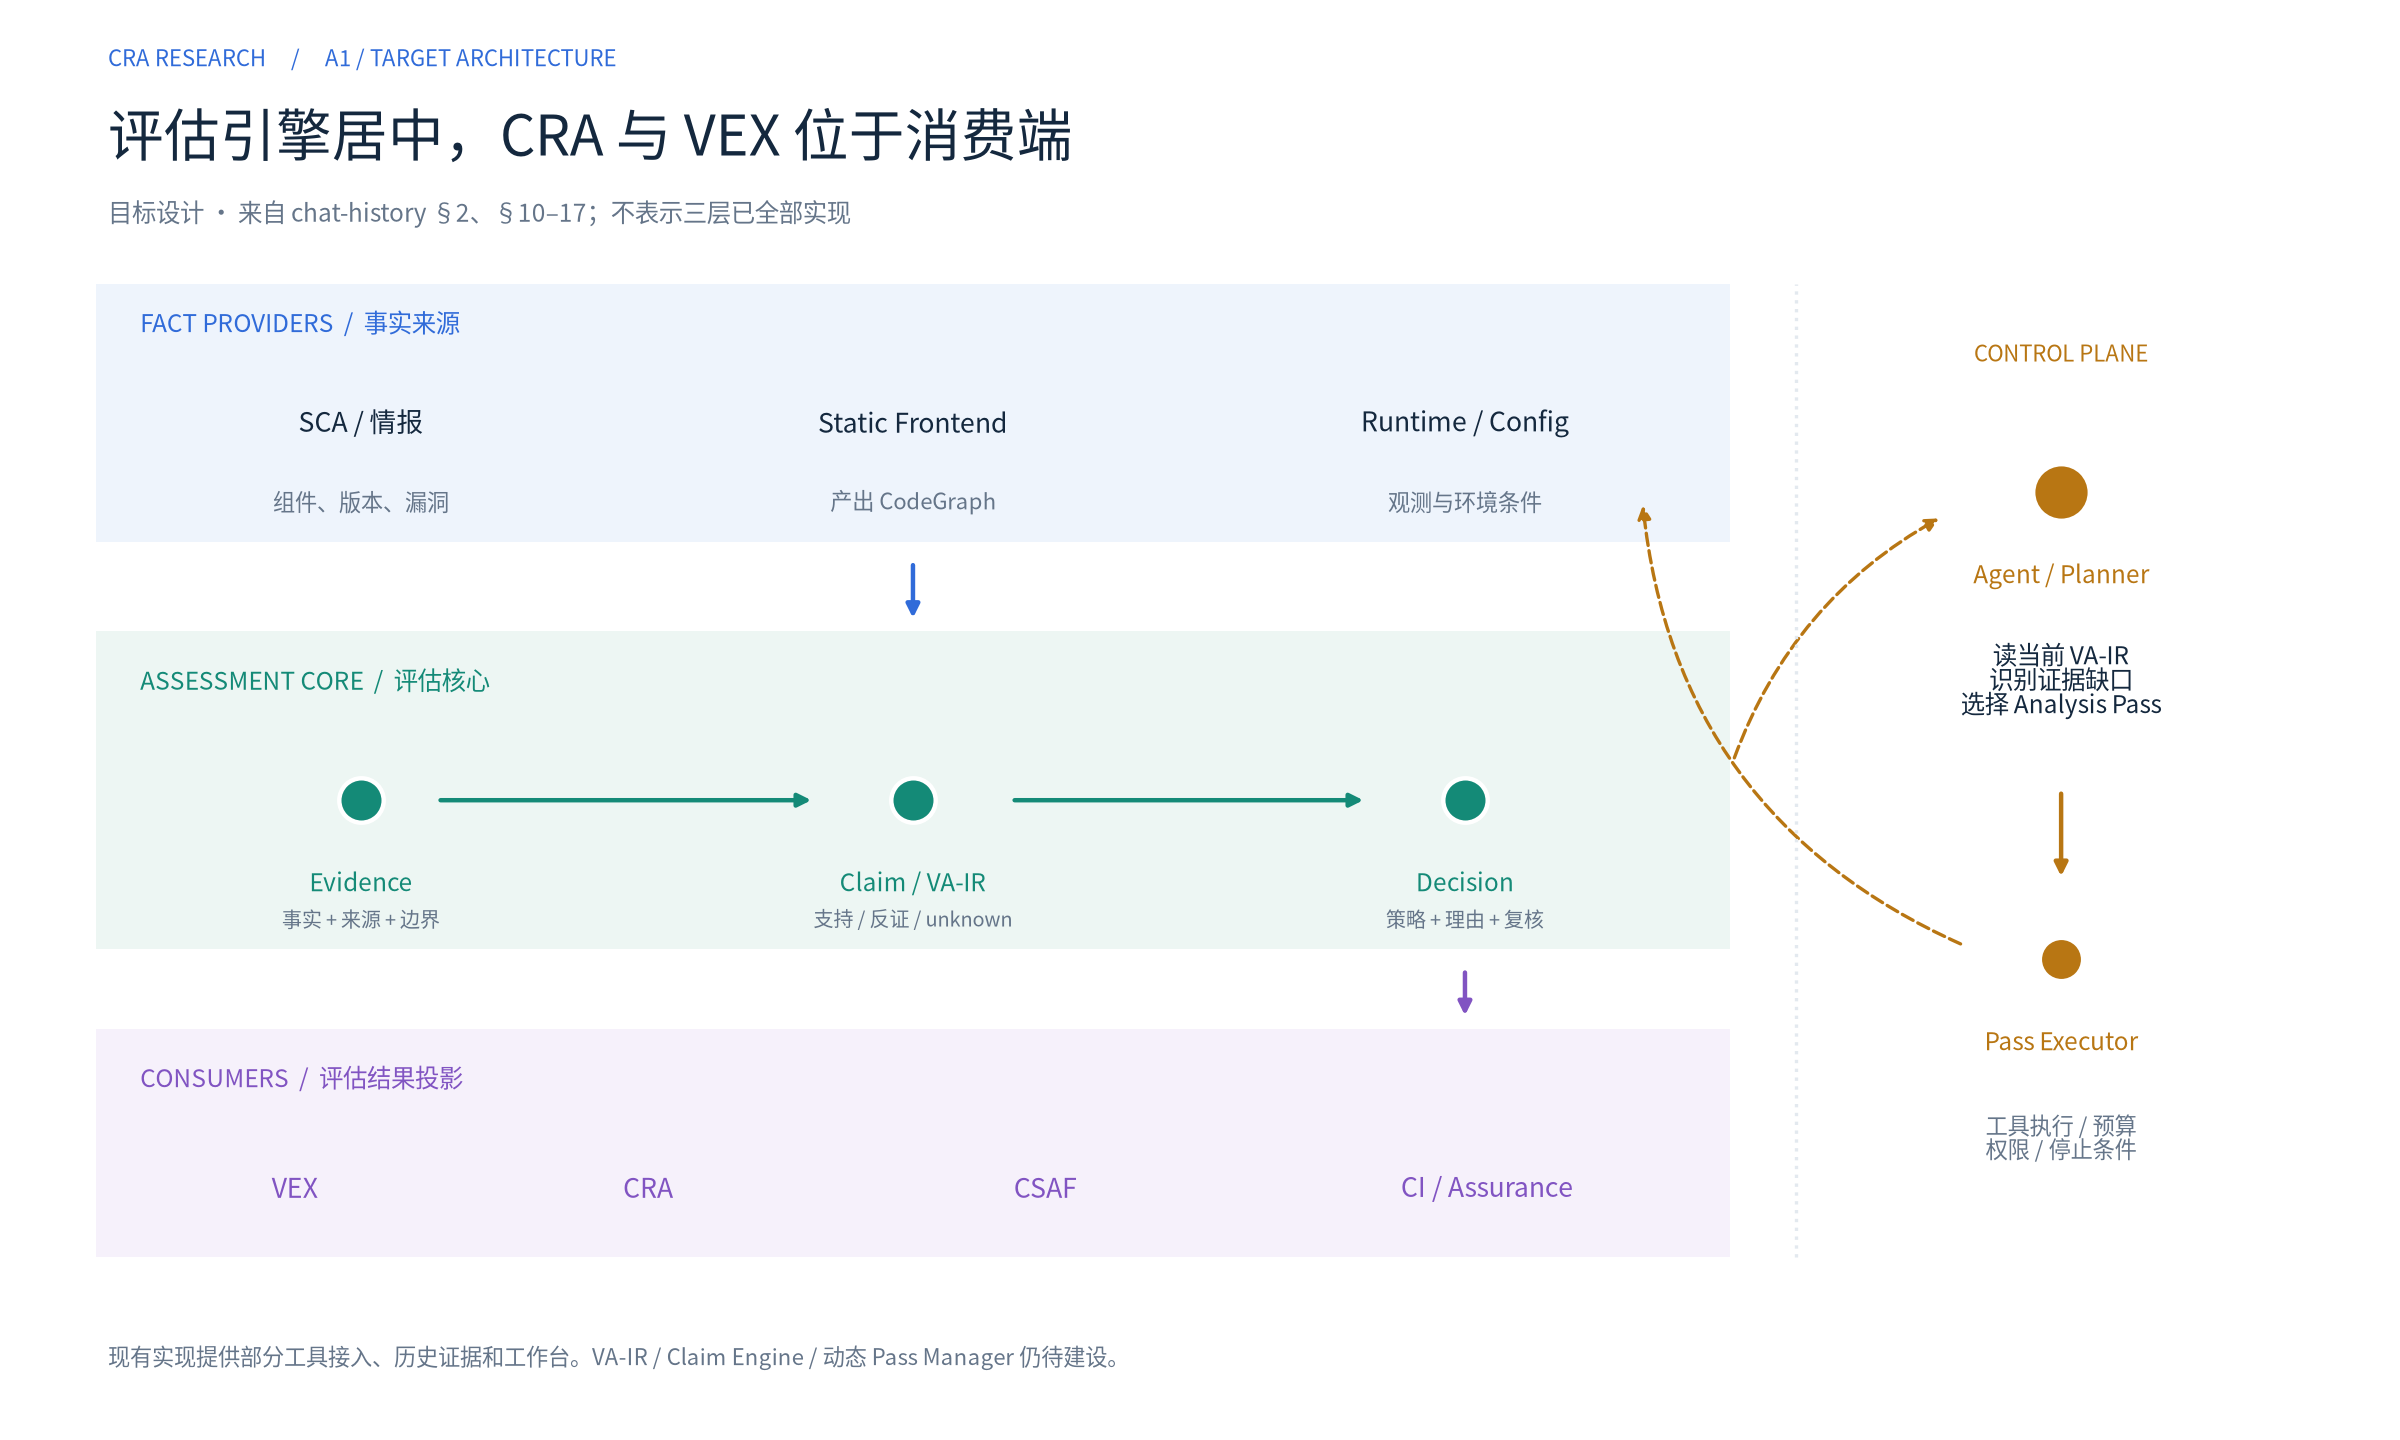

In [2]:
from cra.assessment_figures import build_assessment_figure
import matplotlib.pyplot as plt
build_assessment_figure(case, 'architecture')
plt.show()

> **判读：** 换成 CRA、VEX 或 CI，不应重写分析核心。Agent 也不能绕过工具证据和决策策略，直接宣称“不受影响”。当前 Store 与工作台覆盖其中的一部分，不等于图中的完整引擎已经实现。

## 02 · CVE 不能直接交给 CallGraph

**历史材料＋人工策展。** SCA 关联指向组件和漏洞；调用图接受的是符号、入口与程序基线。中间需要 Localization，绑定文件、符号、必要时的代码区域及修复引用。

本例的 SBOM 中 zlib 由人工增补声明；漏洞到 `inflate` 的映射也来自人工策展。它们是真实保存的输入，但不能包装成自动识别与自动定位。


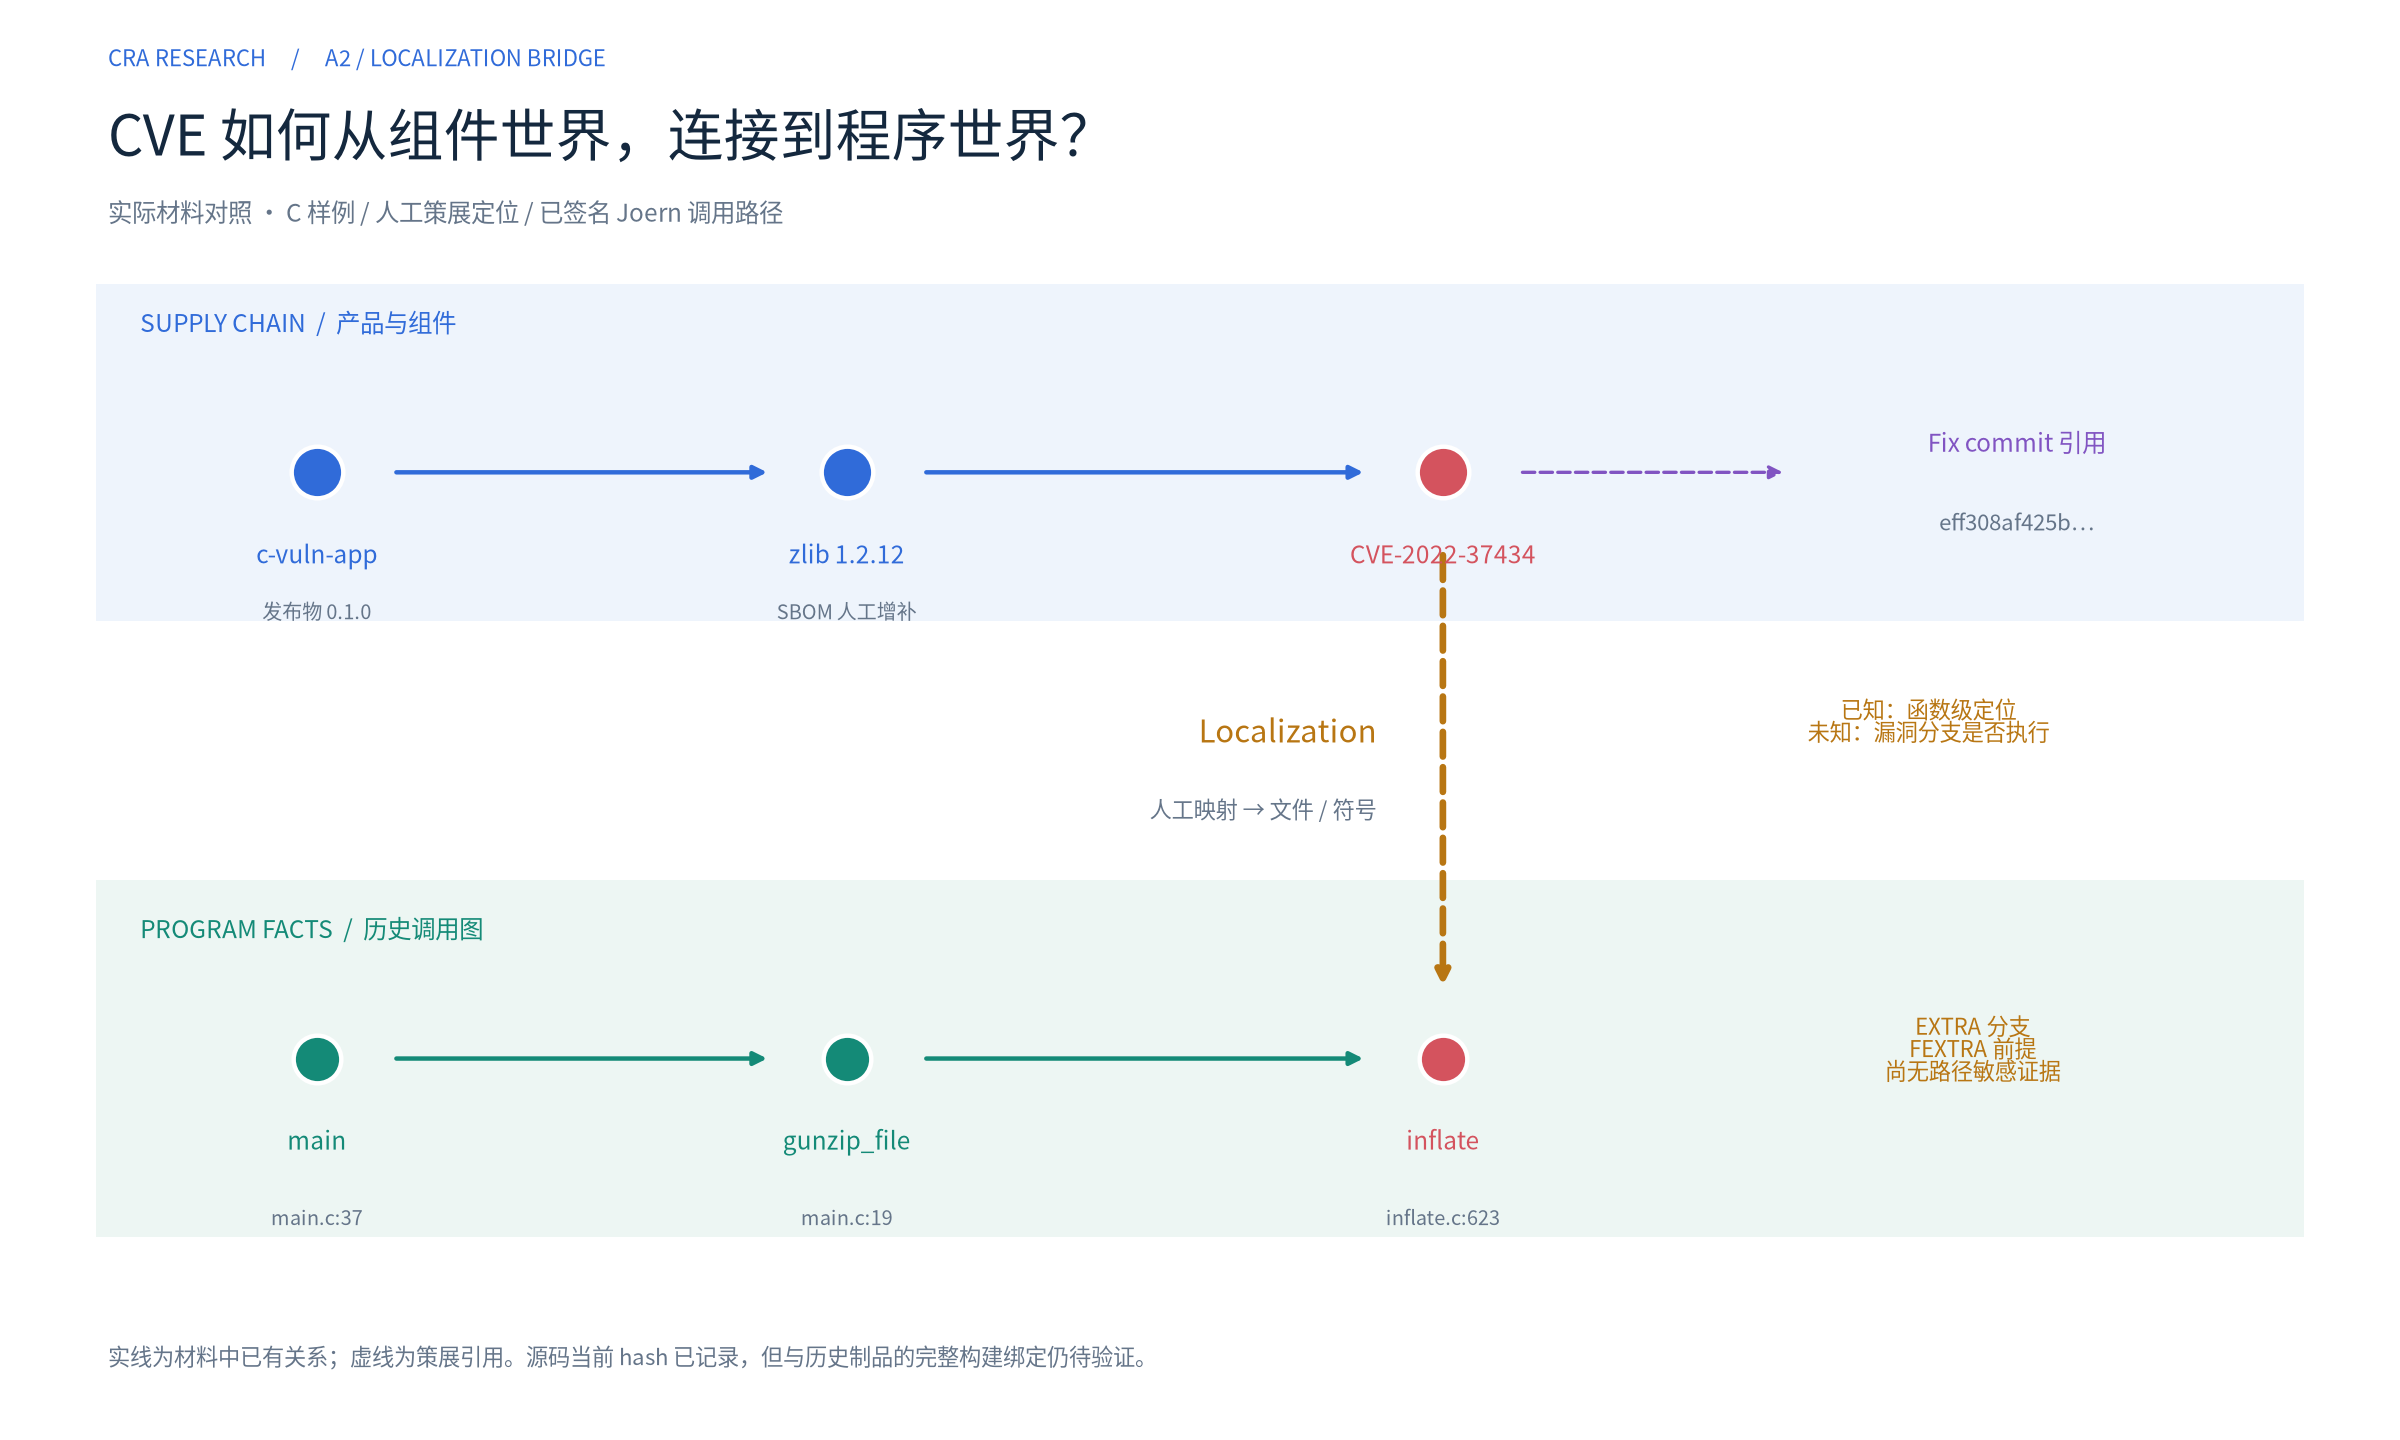

In [3]:
from cra.assessment_figures import build_assessment_figure
import matplotlib.pyplot as plt
build_assessment_figure(case, 'localization')
plt.show()

In [4]:
observations = case["observations"]
print("目标组件：", case["subject"]["component"])
print("漏洞：", case["subject"]["vulnerability"])
print("定位方式：", observations["localization"]["method"])
print("文件：", observations["localization"]["file"])
print("符号：", observations["localization"]["symbol"])
print("策展文件 SHA256：", observations["localization"]["curation_sha256"])
print("已签名历史路径：", " → ".join(observations["reachability"]["path"]))
print("仍缺：当前源码与历史制品的完整构建绑定；漏洞分支执行证据。")

目标组件： pkg:generic/zlib@1.2.12
漏洞： CVE-2022-37434
定位方式： manual curation; NOT automated localization
文件： third_party/zlib/inflate.c
符号： inflate
策展文件 SHA256： b986c4a1929e8889798de015a2383ac43b3141afb4d6af0c5d4334679532c046
已签名历史路径： main → gunzip_file → inflate
仍缺：当前源码与历史制品的完整构建绑定；漏洞分支执行证据。


> **判读：** 当前证据到达了“记录中的结构路径存在”。函数可达，不等于进入漏洞分支，更不等于攻击者可控输入已经满足利用条件。补充的 Go 调用网络见后文实测附录。

## 03 · 用 Claim 表达证据能支持到哪里

**设计投影。** 同一条调用路径可支持“在所记录图中结构可达”，但不能同时支持“当前部署可利用”。Evidence、Claim 和 Decision 分开，避免一个 VEX status 吞掉所有中间判断。


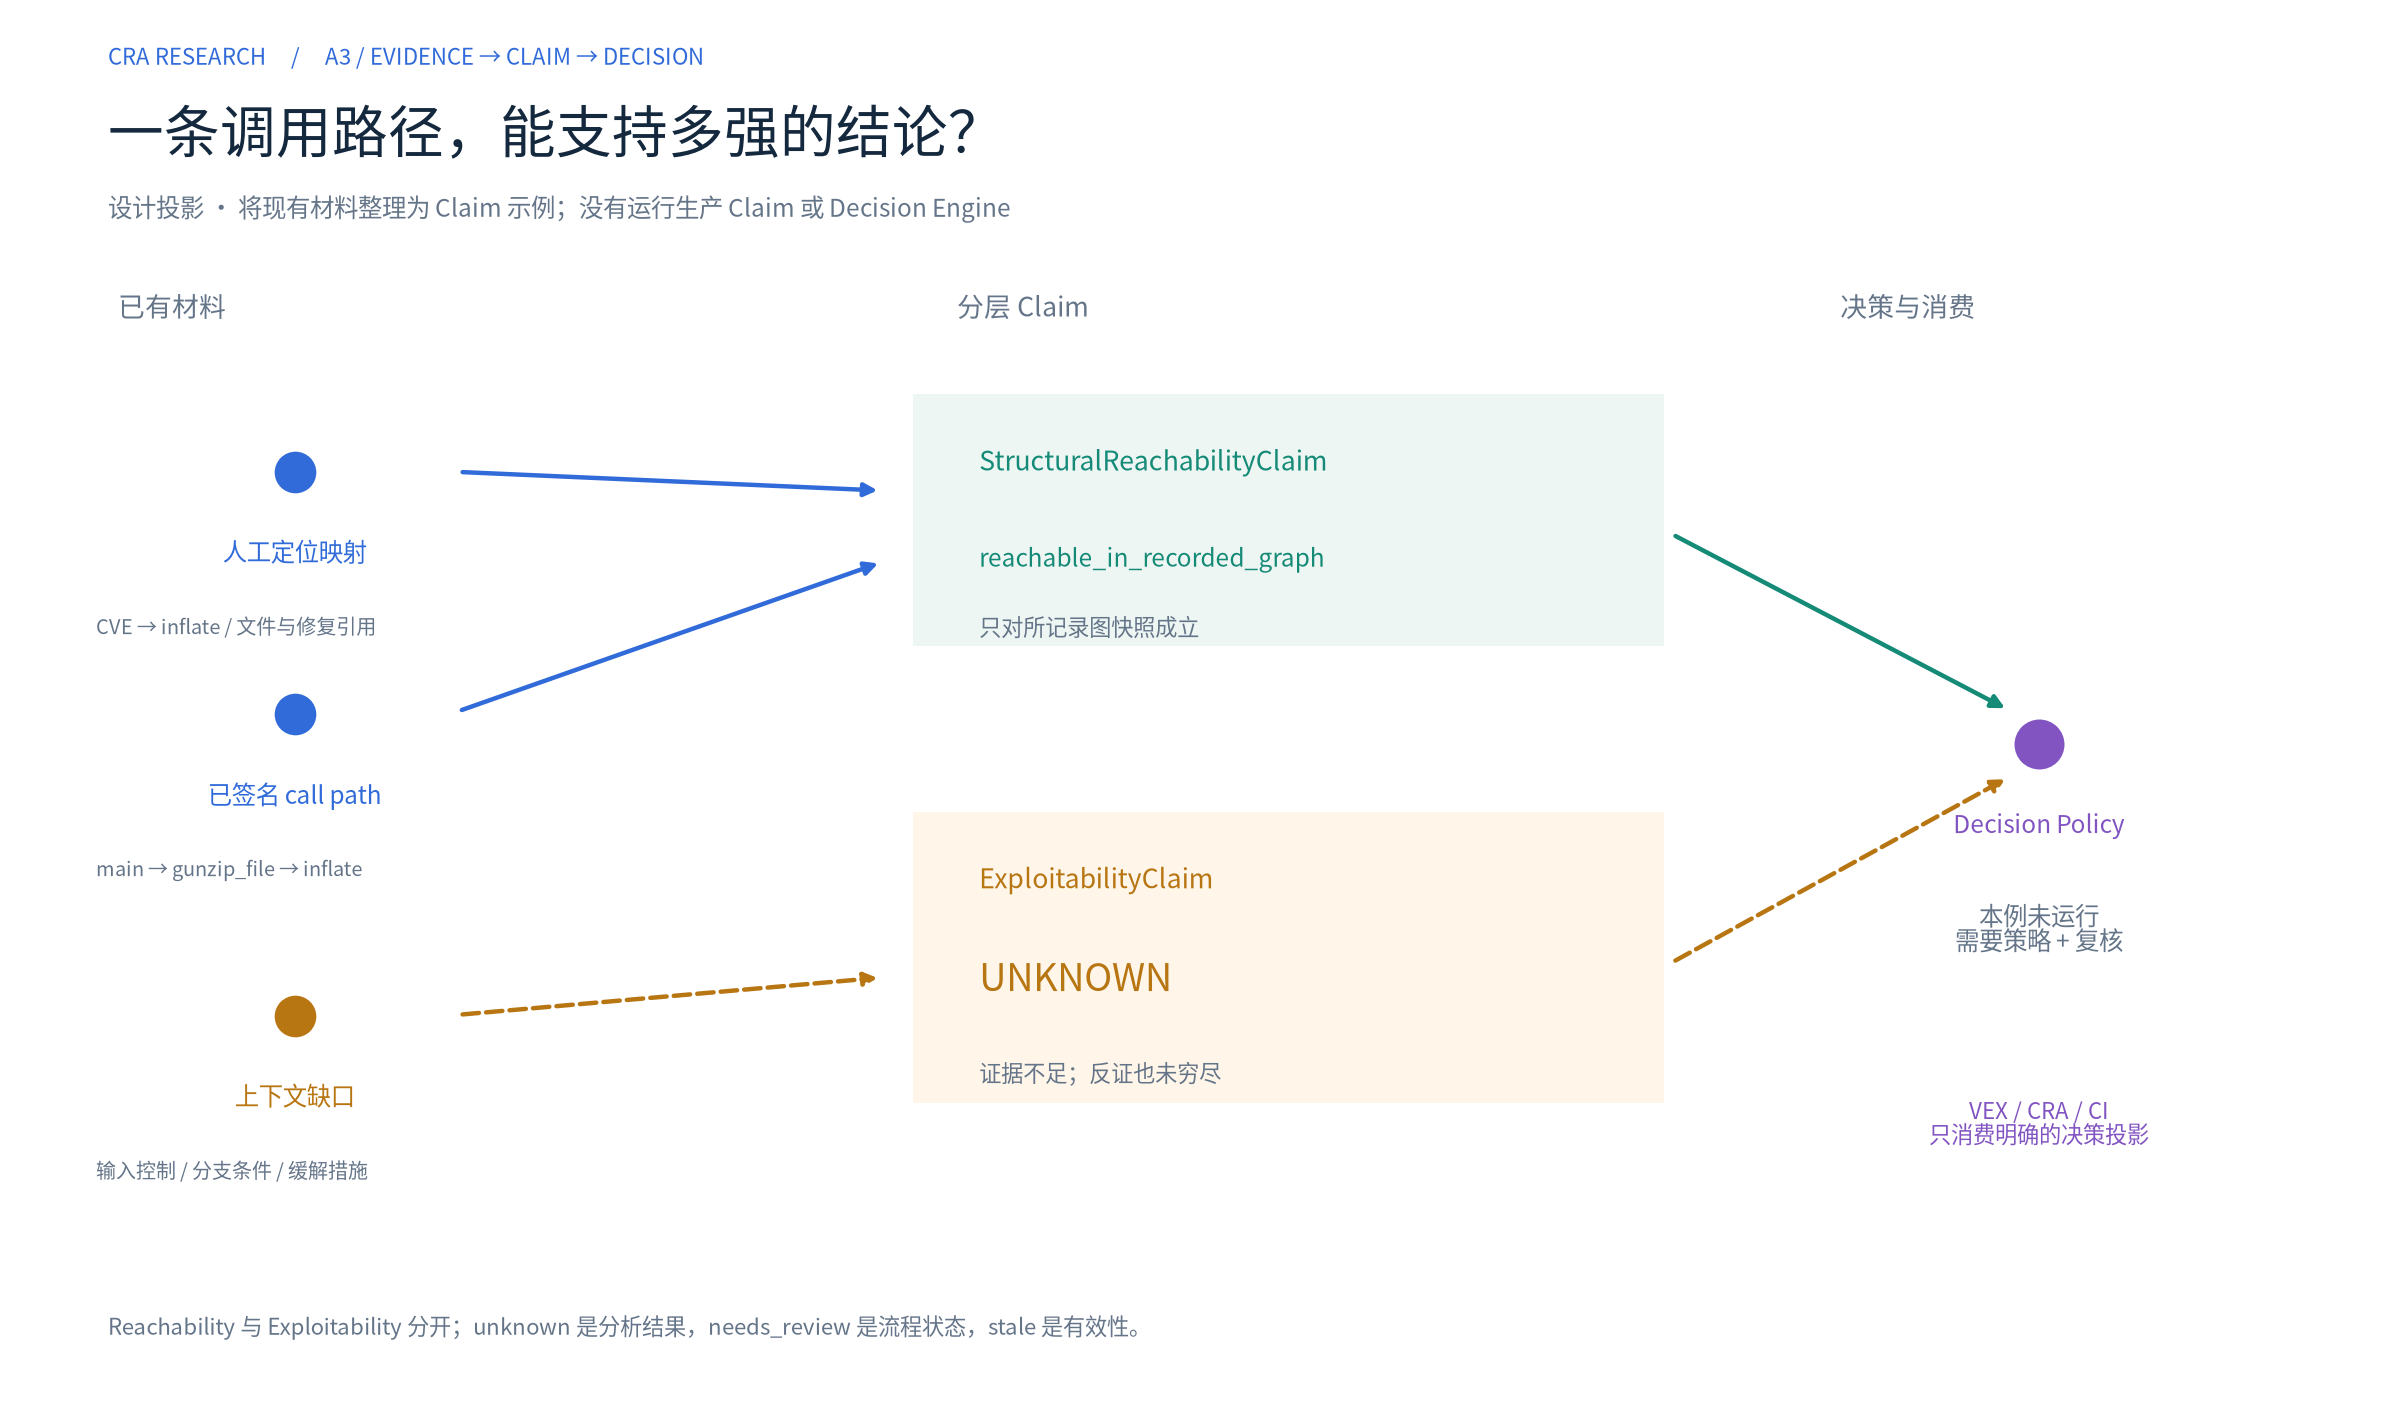

In [5]:
from cra.assessment_figures import build_assessment_figure
import matplotlib.pyplot as plt
build_assessment_figure(case, 'claims')
plt.show()

### VA-IR 示例：保持未知项可见

以下 JSON 由本例材料整理，**只存在于演示内存中，没有写入运行时 Store，也未成为正式判定**。`counter_evidence: []` 表示本投影未收集反证，不表示已证明没有反证。

| 维度 | 本例含义 |
|---|---|
| assertion | 具体主张，限定在所记录图的结构路径 |
| unknowns | 当前制品绑定、漏洞分支及运行条件尚未解决 |
| sufficiency | 证据足以支持哪个层次 |
| validity | 对哪份历史快照有效 |
| review | 是否完成人审，独立于技术结论 |


In [6]:
print(json.dumps({
    "mode": case["mode"],
    "subject": case["subject"],
    "claims": case["claims"],
    "decision": case["decision"],
}, ensure_ascii=False, indent=2))

{
  "mode": "read-only-design-projection",
  "subject": {
    "product": "c-vuln-app",
    "version": "0.1.0",
    "artifact_sha256": "4332f06c17d5ef7e97061a8b0433331ad74ddd5d6474f89fd6fbe0f5d7ba82d7",
    "component": "pkg:generic/zlib@1.2.12",
    "vulnerability": "CVE-2022-37434",
    "context": "historical Joern graph / entry main"
  },
  "claims": [
    {
      "id": "demo-claim-reachability",
      "type": "structural_reachability",
      "assertion": "reachable_in_recorded_graph",
      "supporting_evidence": [
        "evidence-6f4c1aef505b04e5496dbaff75e8ea6dd735fca96efd9d6d69e67188ec3b4e5e"
      ],
      "counter_evidence": [],
      "counter_evidence_note": "not evaluated exhaustively",
      "unknowns": [
        "current source-to-historical-artifact binding",
        "vulnerable branch execution"
      ],
      "sufficiency": "supports recorded structural path only",
      "validity": "historical_snapshot_only",
      "review": "not_performed",
      "policy": "illustrat

## 04 · Agent 要演示的是“证据驱动的下一步”

**脚本化设计推演。** 下面预设三轮用于解释 Pass Manager。程序读取现有映射和历史路径来说明可能如何推进，没有模型选择，也没有实际调用 Localization/Reachability 工具。

真正的 Agent 实验还需要：Pass 的 requires/produces、工具执行记录、预算、权限、失败与停止原因。


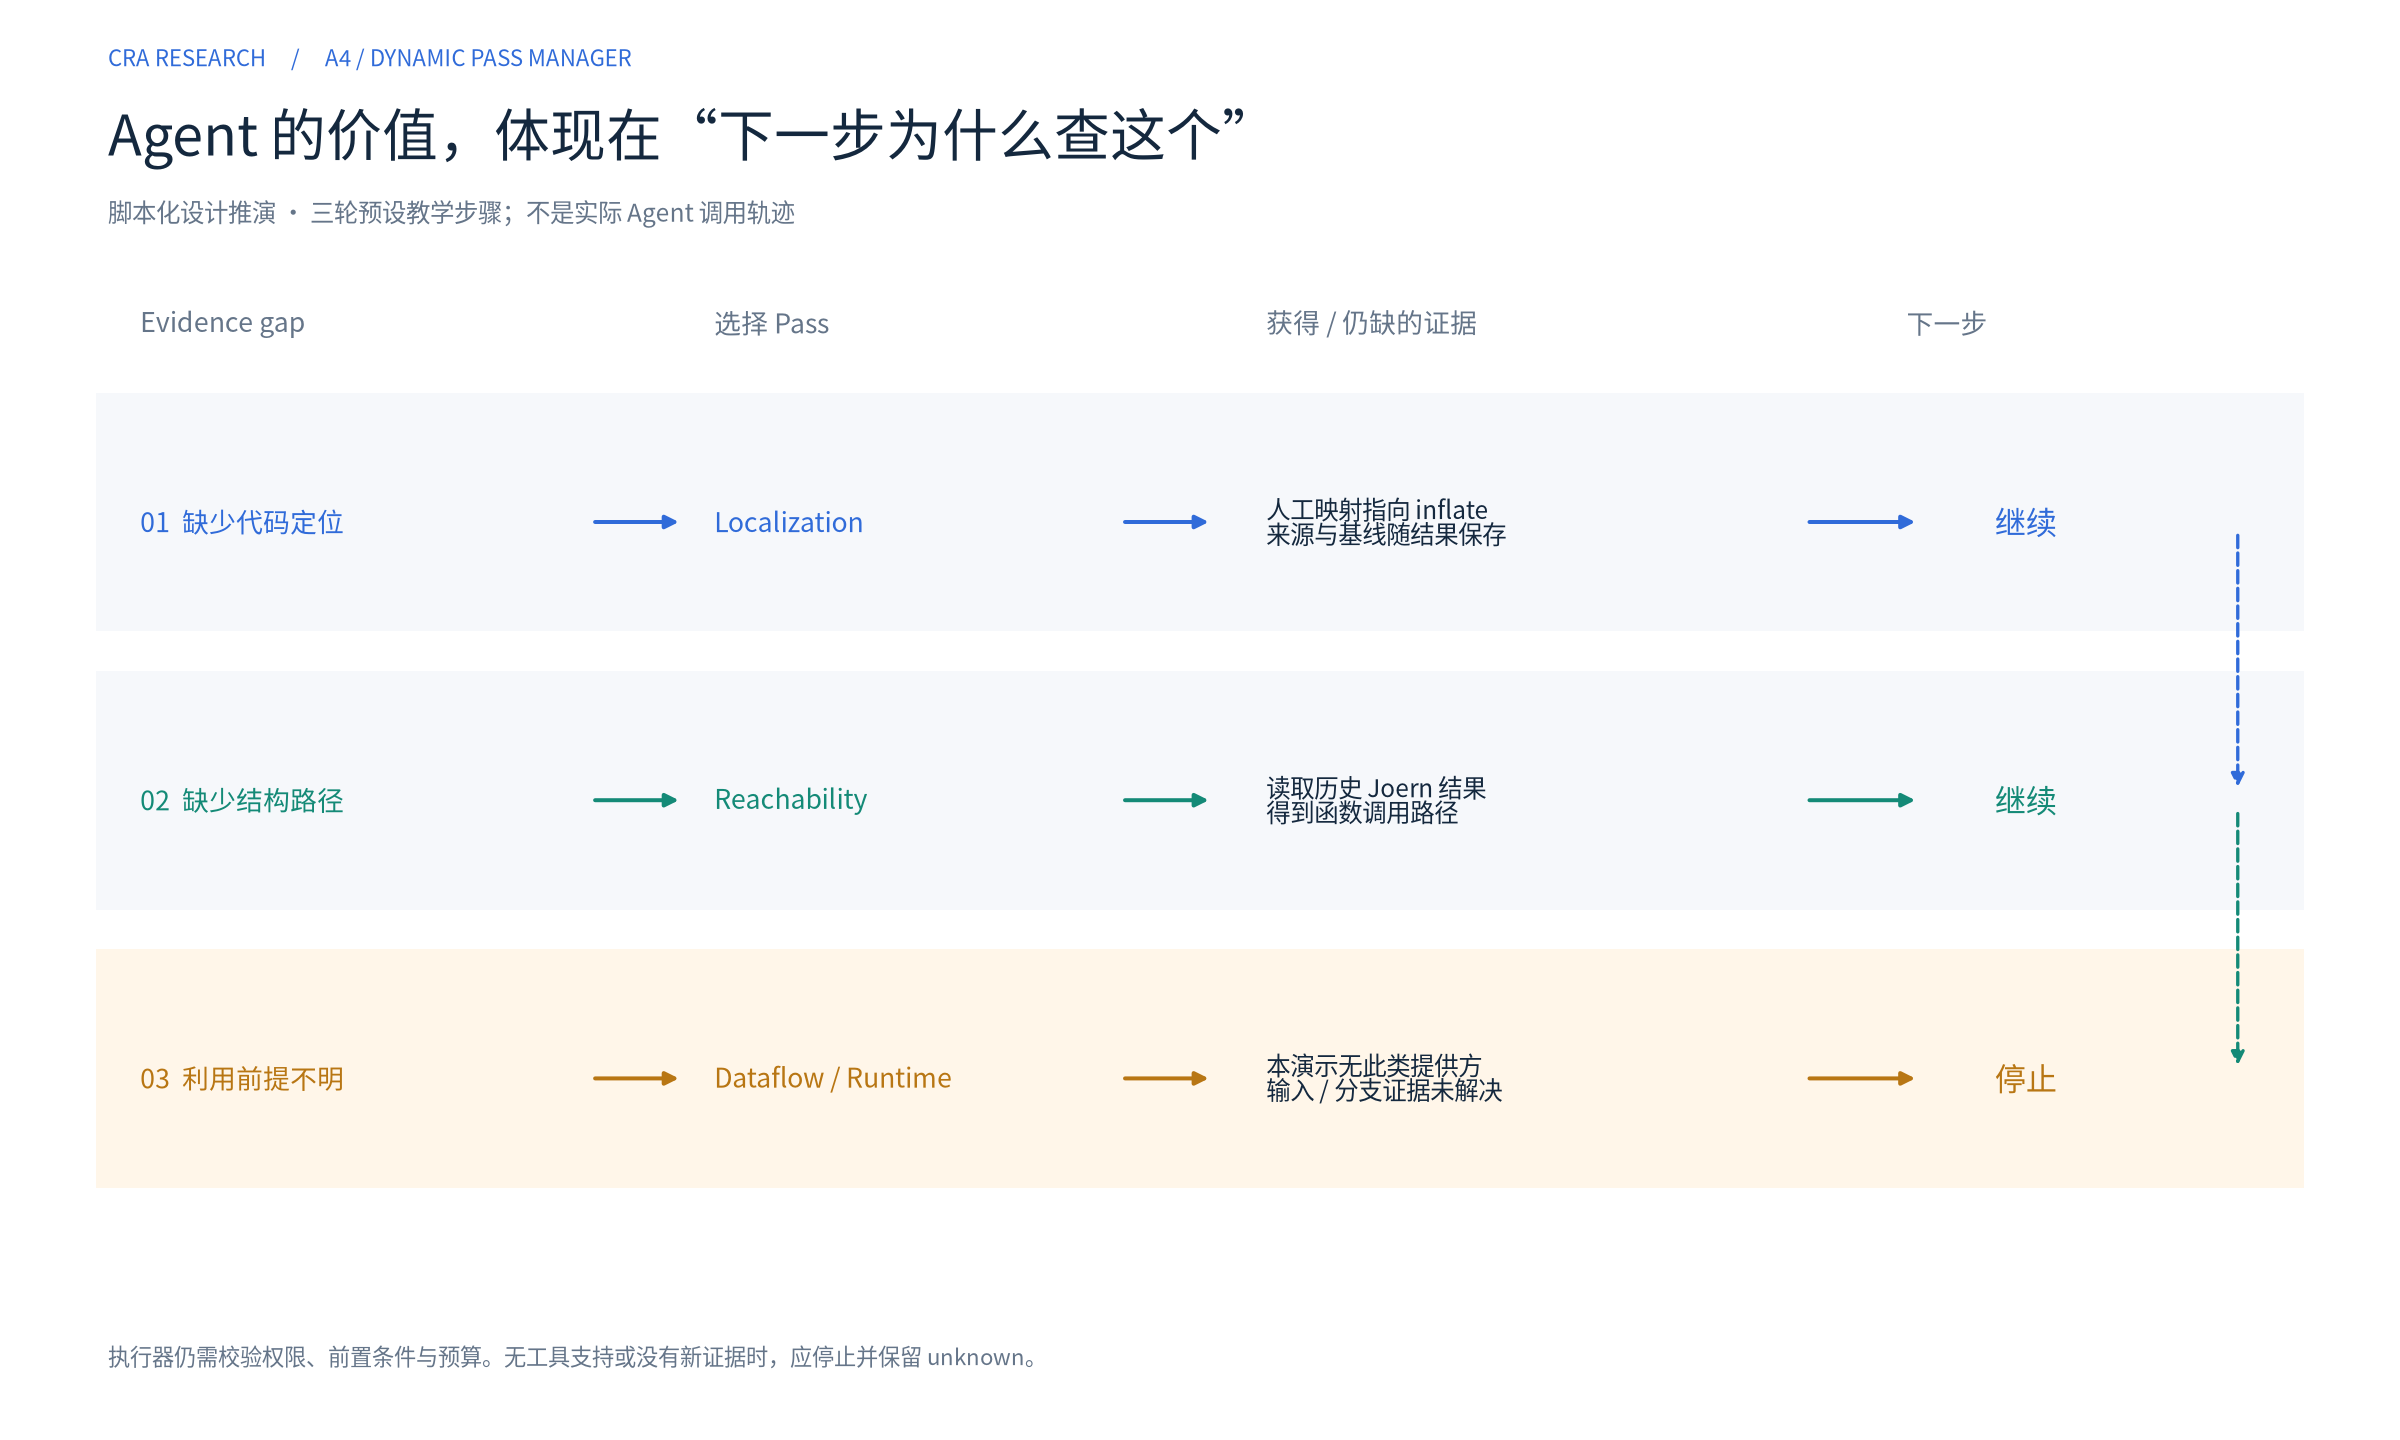

In [7]:
from cra.assessment_figures import build_assessment_figure
import matplotlib.pyplot as plt
build_assessment_figure(case, 'planner')
plt.show()

In [8]:
for step in case["planner_trace"]:
    print(f"轮次 {step['round']} [{step['mode']}]")
    print("  缺口：", step["gap"])
    print("  建议能力：", step["proposed_pass"])
    print("  结果：", step["result"])

轮次 0 [scripted-design-walkthrough]
  缺口： CVE not yet bound to symbol
  建议能力： Localization
  结果： inflate candidate with provenance
轮次 1 [scripted-design-walkthrough]
  缺口： No structural path in assessment
  建议能力： Reachability
  结果： import existing main → gunzip_file → inflate evidence
轮次 2 [scripted-design-walkthrough]
  缺口： Input and vulnerable branch conditions unresolved
  建议能力： Dataflow / Runtime
  结果： stop with unknown + needs_review


> **判读：** “没有工具支持下一项分析”是合法停止条件。应返回 unknown / needs_review，而不是为了结束流程，强行给出 affected 或 not_affected。图中的三轮是待实现协议的教学示例，不是 Agent 效果展示。

## 05 · 闭环的关键：证据变化会让哪些判断失效？

**合成依赖例子。** 假设只换了源码快照，SBOM 和 advisory 保持不变。教学函数计算依赖传播；它没有接到 `Store.reassess()` 或持续监控。

失效意味着需要重算，不代表原结论自动反转。旧快照、旧 Claim 和当时的决策仍应保留。


In [9]:
invalidation_example = illustrate_invalidation("source_snapshot")
print("演示类型：", invalidation_example["mode"])
print("输入变化：", invalidation_example["changed"])
print("标记 stale：", ", ".join(invalidation_example["stale"]))
print("本例不受影响：", ", ".join(invalidation_example["unaffected"]))

演示类型： synthetic-dependency-example
输入变化： source_snapshot
标记 stale： codegraph_snapshot, decision, localization_claim, reachability_claim, vex_projection
本例不受影响： advisory_snapshot, association_claim, component_inventory


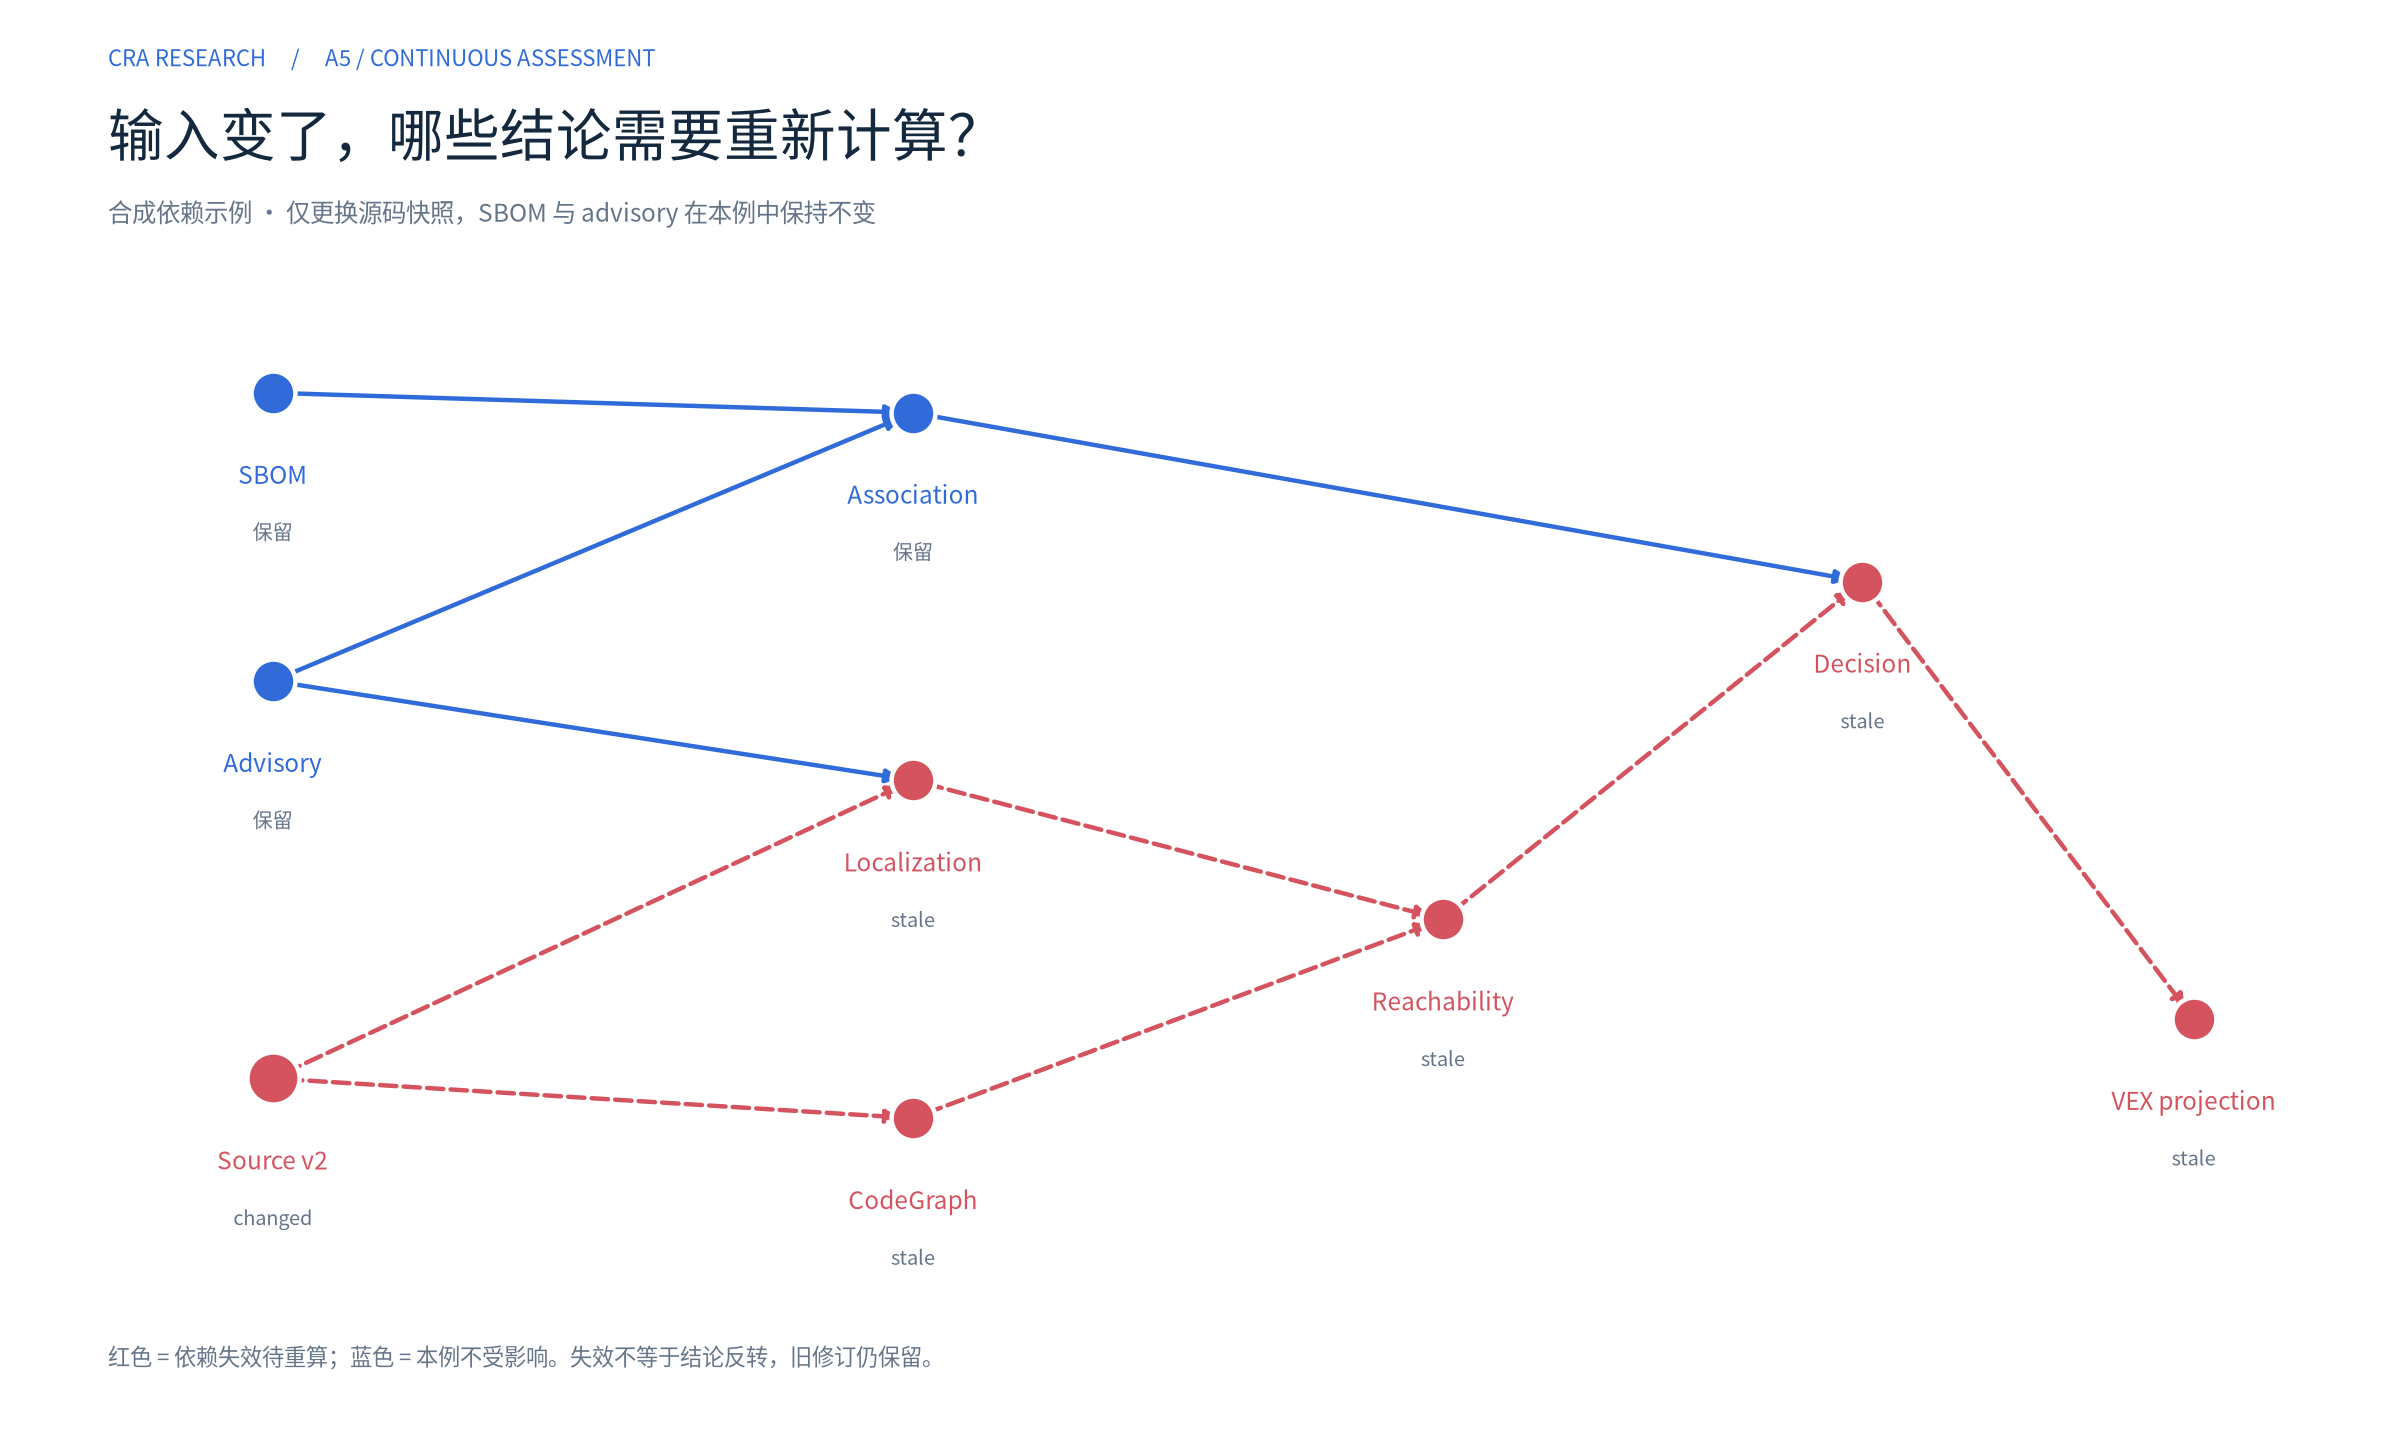

In [10]:
from cra.assessment_figures import build_assessment_figure
import matplotlib.pyplot as plt
build_assessment_figure(invalidation_example, 'invalidation')
plt.show()

> **判读：** Localization、CodeGraph、Reachability、Decision 和 VEX 投影沿依赖失效；组件清单和独立 advisory 关联不必无差别重跑。若 SBOM 也变了，失效范围必须相应扩大。

## 06 · CRA / VEX / CI 消费什么？

**目标接口。** 消费端读取明确的 Decision 修订及其 Claim、Evidence 来源。内部 `unknown`、`stale`、`needs_review` 等维度不能直接照搬成外部 VEX 枚举。

| 消费方 | 从核心取什么 | 消费方自己的职责 | 当前状态 |
|---|---|---|---|
| VEX adapter | 判定、产品身份、依据、版本 | 格式与理由映射、批准与签发 | 原始 VEX 可导入；新判定未正式签发 |
| CRA workflow | 评估证据、修复验证、产品快照 | 事件适用性、时钟、报告与回执 | 已有本地流程原型；非完整合规平台 |
| CI Gate | 策略允许消费的有效决策 | 按构建/发布策略执行门禁 | 待实现 |
| CSAF / Assurance | 决策与来源引用 | 通告与其他保证流程 | 待实现 |

本次只能导出**已有工作台的内部复核包**。下列命令验证的是该能力，没有把上面的 VA-IR 教学投影当作生产评估写进去。


In [11]:
bundle = Path(workspace.name) / "review-bundle"
store.export(bundle)
assert store.snapshot() == snapshot, "Teaching projection must not mutate the workbench"
print("内部复核包导出与复验通过；教学投影没有修改工作台记录。")
print("真实事件数：", len(snapshot["incidents"]), "本次复核数：", len(snapshot["reviews"]))
store.db.close()
workspace.cleanup()

内部复核包导出与复验通过；教学投影没有修改工作台记录。
真实事件数： 0 本次复核数： 0


## 07 · 这份演示验证了什么，还没验证什么？

| 内容 | 结论 |
|---|---|
| 从签名记录读取真实路径和历史验证 | 已回放并校验 |
| 人工 Localization 连接组件/CVE 与符号 | 已展示输入来源和局限 |
| 用 Claim 描述支持证据与 unknowns | 完成只读教学投影，非生产 schema |
| Agent 动态选择 Pass | 尚未验证；目前仅预设推演 |
| 输入变化沿依赖失效 | 合成图演示；未接持续事件 |
| 同一 Decision 投影多个消费端 | 架构目标；尚未实现完整适配链 |

下一轮工程验证应围绕 **Localization → Claim/VA-IR → Pass 调度 → Decision/Adapter → 失效重估**，而非继续扩展报告页面。

---

## 实测附录 A · Go 调用网络

合并历史 affected 记录中的函数栈。红色是 Terrapin 路径，其他分支来自同一份历史证据集。这里没有声称分析器已覆盖全部程序路径。


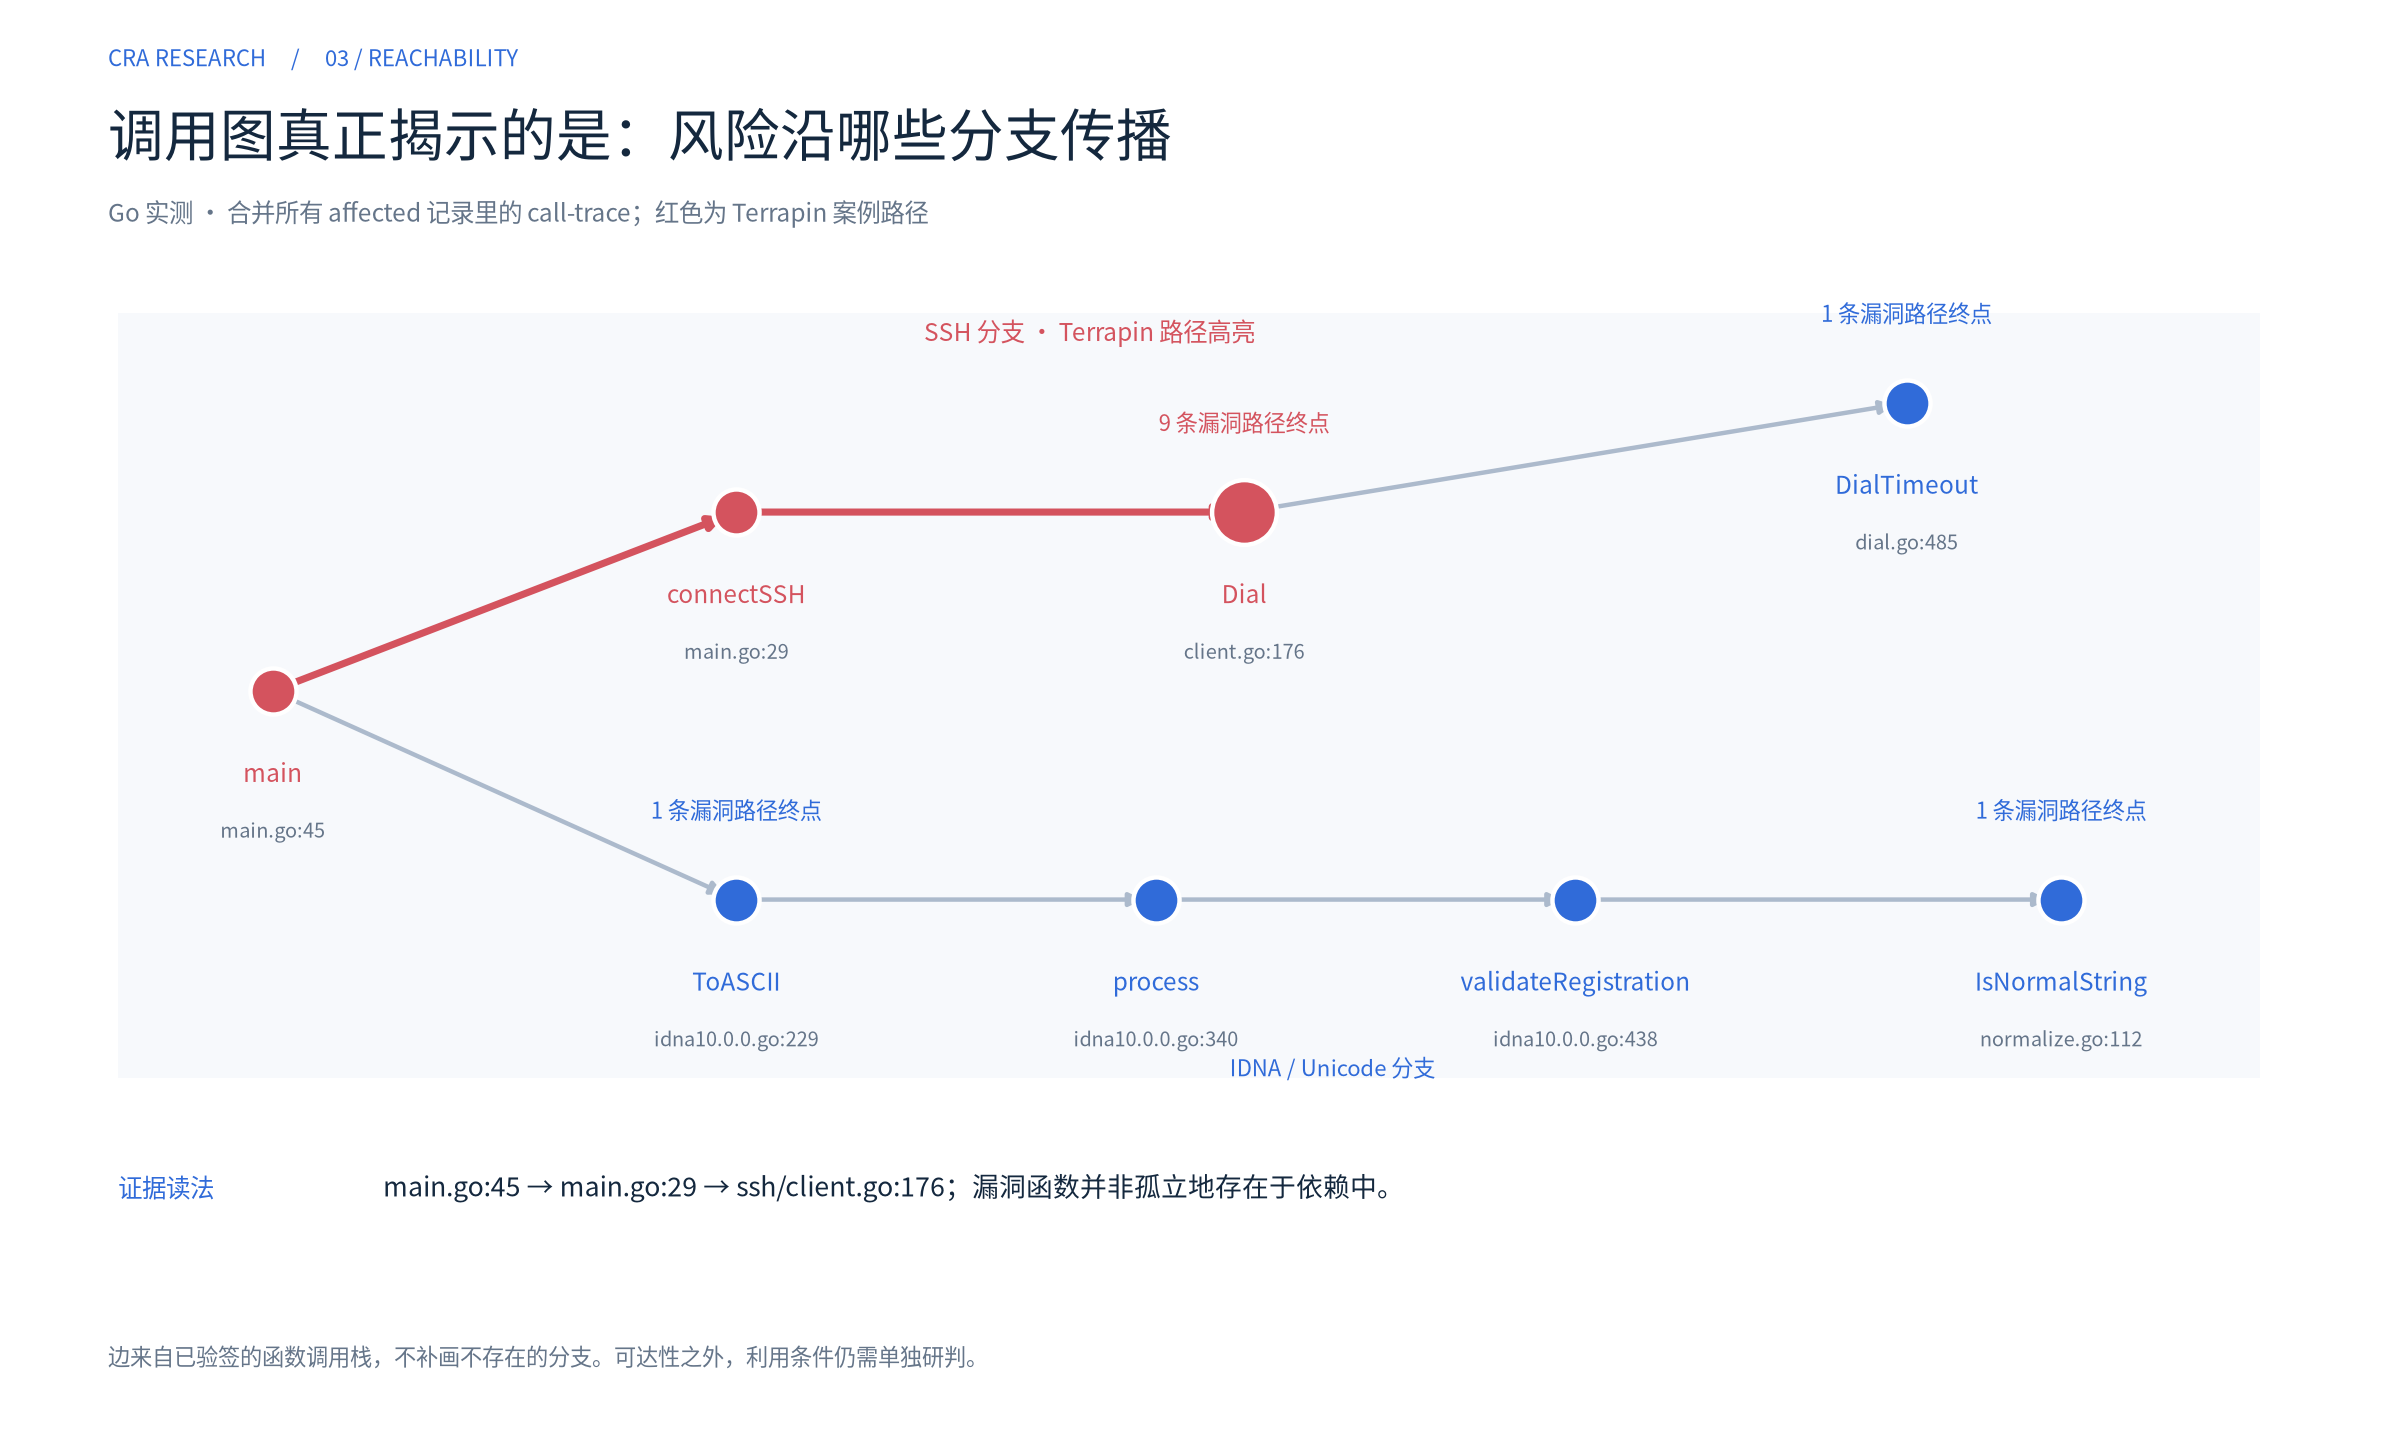

In [12]:
from cra.notebook_figures import build_figure
import matplotlib.pyplot as plt
build_figure(snapshot, 'callpaths')
plt.show()

## 实测附录 B · 三条漏洞的历史记录

这是**现有工作台对象关系**，不是上文目标 VA-IR 的实现。工具分析、原始 VEX、修复验证描述不同阶段，当前候选仍需复核。


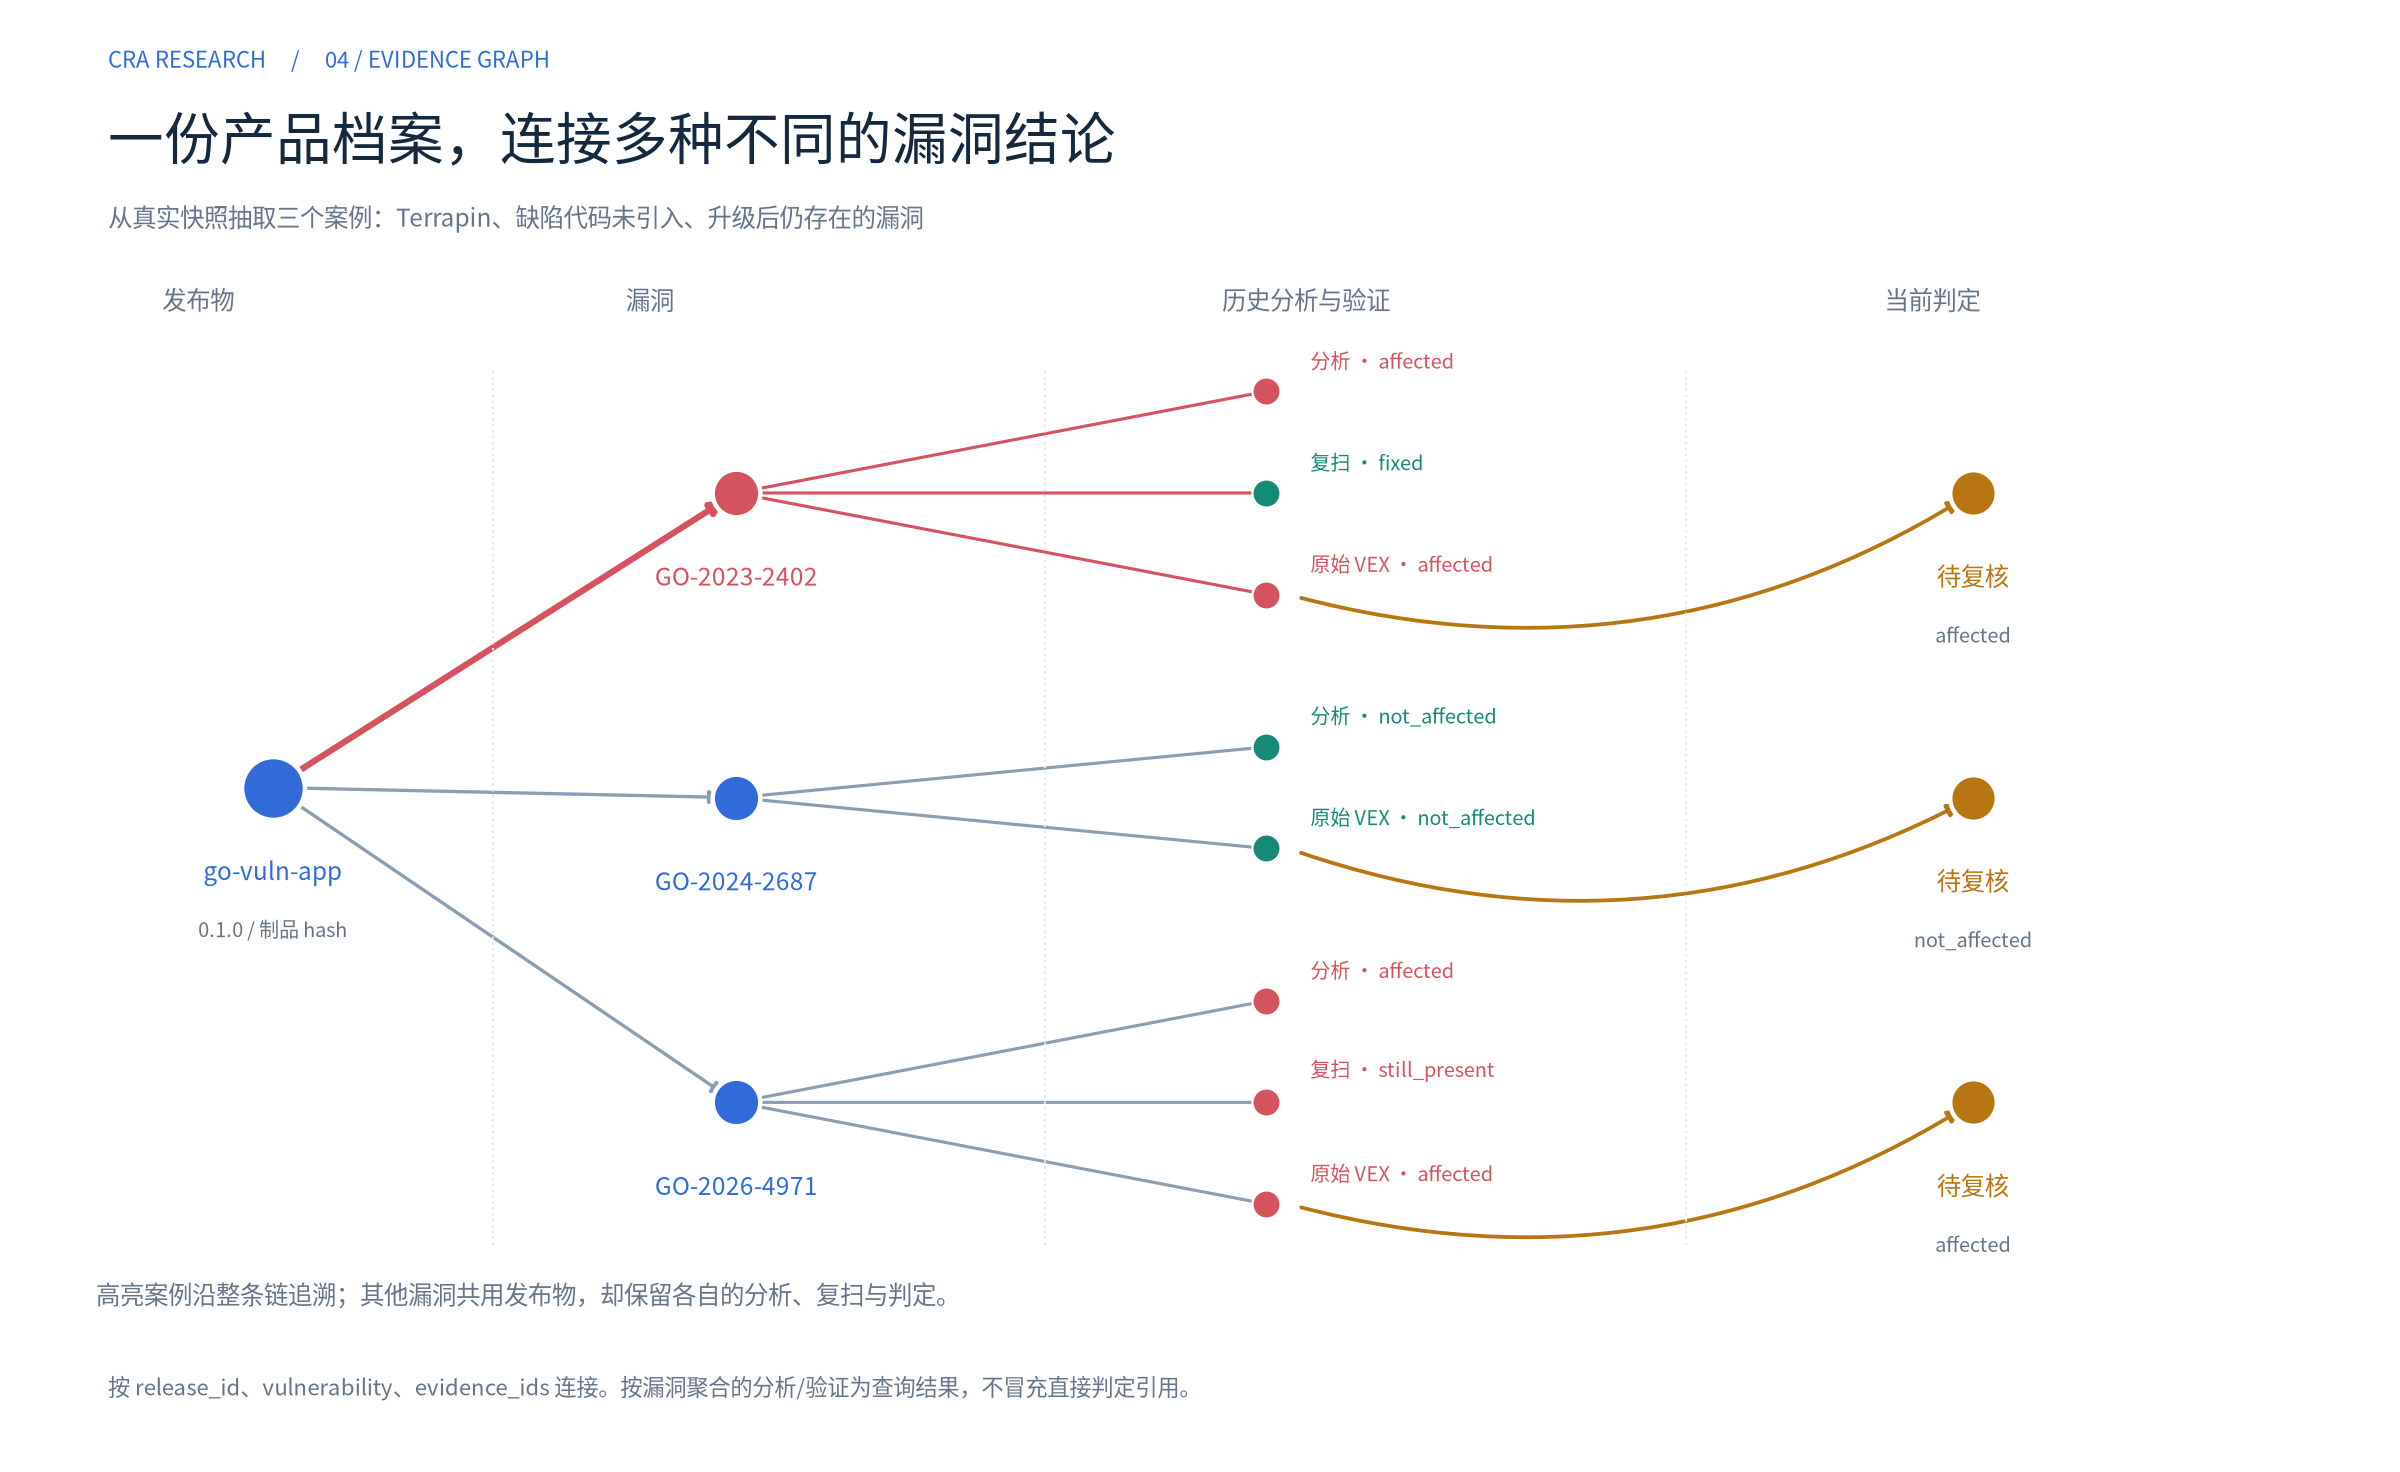

In [13]:
from cra.notebook_figures import build_figure
import matplotlib.pyplot as plt
build_figure(snapshot, 'evidence_graph')
plt.show()

## 实测附录 C · 修复前后逐条对照

12 条原受影响记录的历史复扫；旧发布物记录不因修复而覆盖。


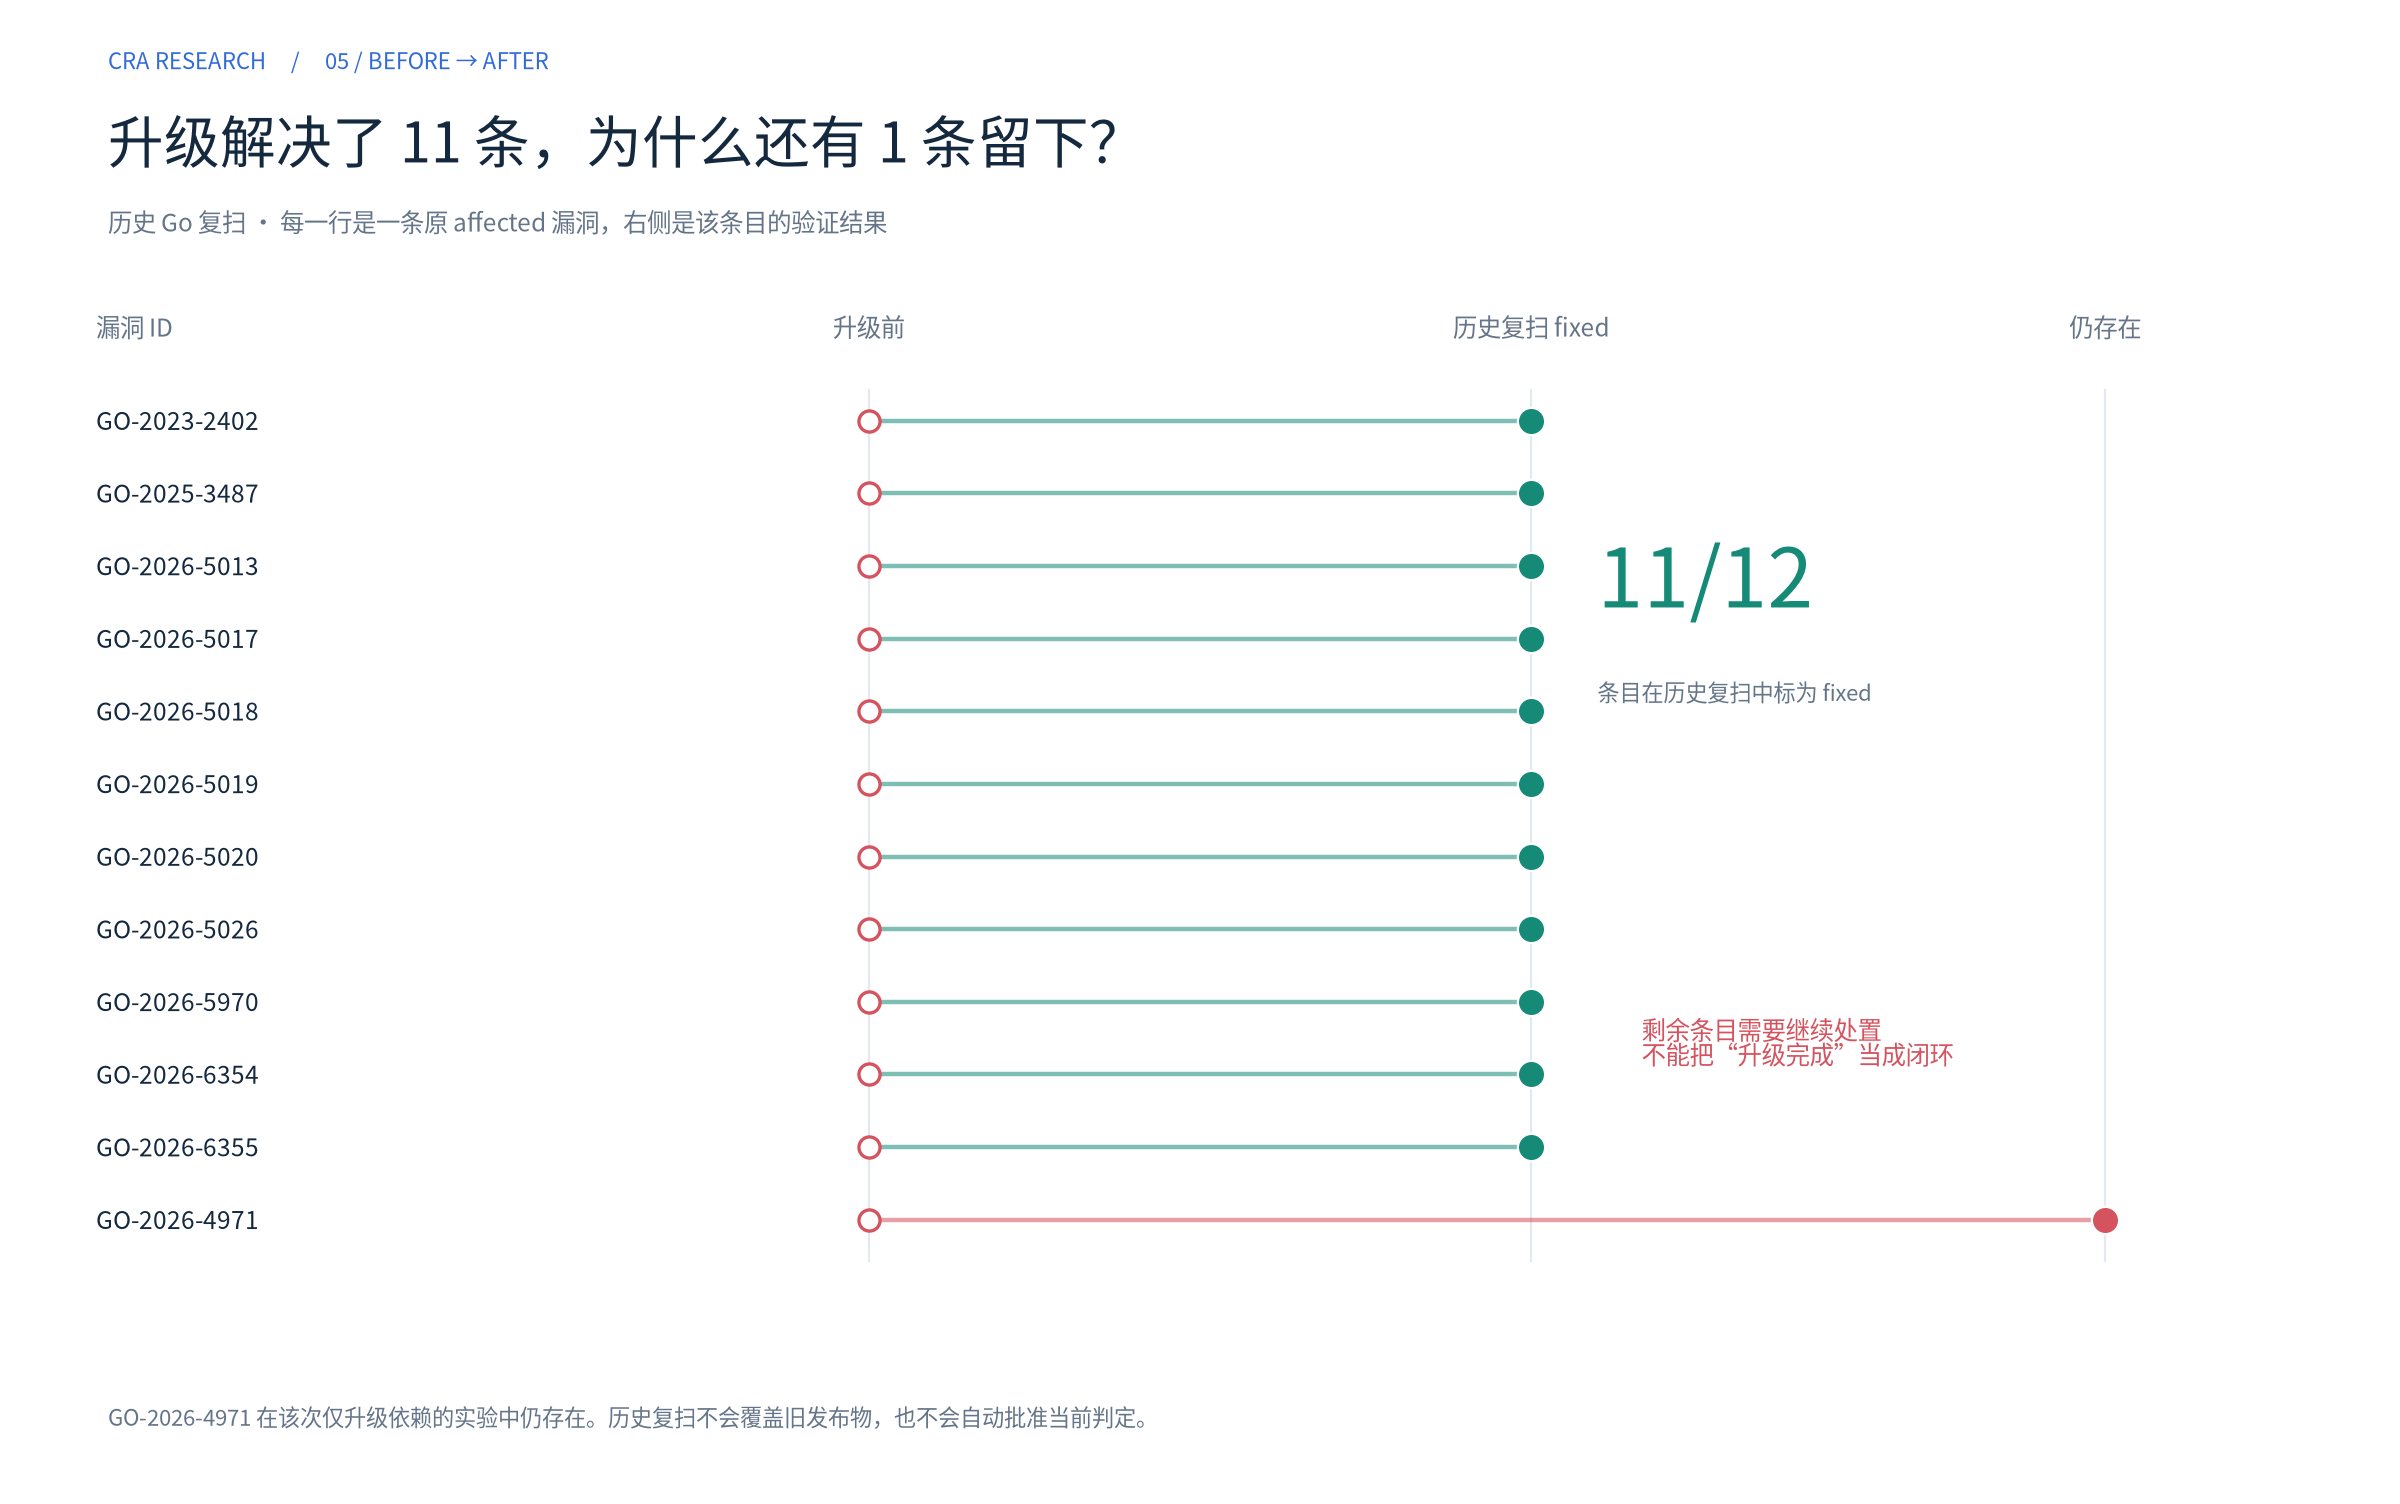

In [14]:
from cra.notebook_figures import build_figure
import matplotlib.pyplot as plt
build_figure(snapshot, 'verification')
plt.show()

## 消费端附录 · CRA 报告时钟

规则示意，不是该案例的真实报告。它属于 CRA Consumer，而非评估核心。


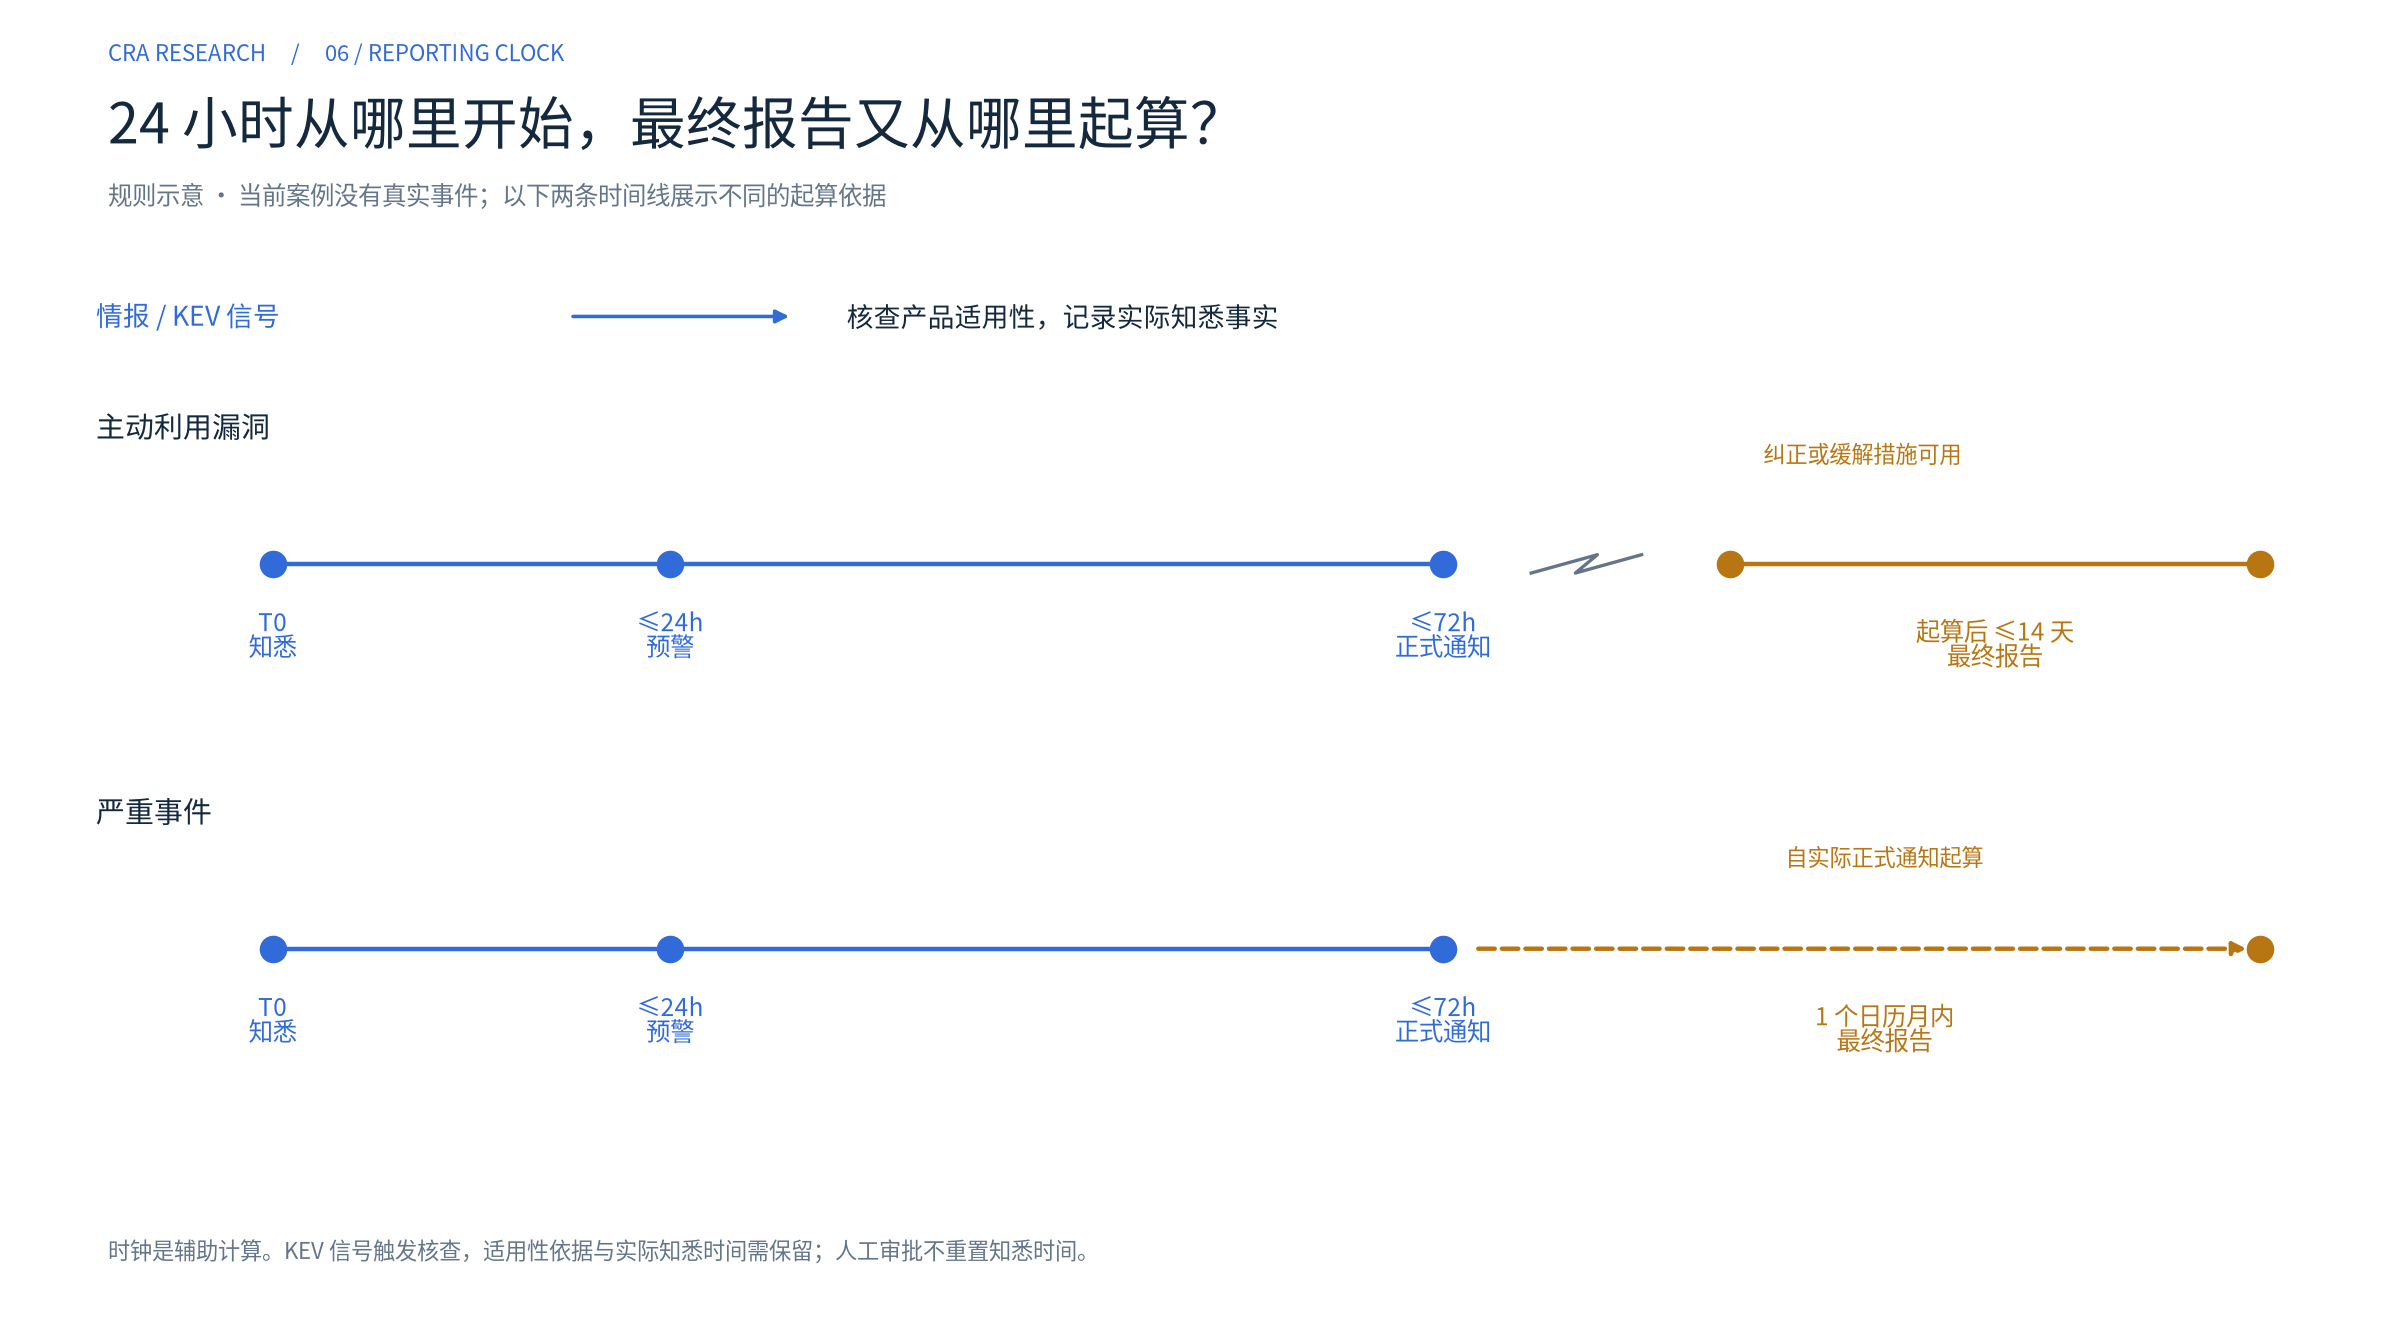

In [15]:
from cra.notebook_figures import build_figure
import matplotlib.pyplot as plt
build_figure(snapshot, 'reporting')
plt.show()

## 数据附录 · 完整判定清单

以下均来自已验签的工作台快照，不是新建的 Claim/Decision 结果。

In [16]:
for j in snapshot['judgments']:
    print(f"{j['vulnerability']:<24} 建议={j['proposed_status']:<20} 当前={j['effective_status']}")

GHSA-45gg-vh54-h5m9      建议=under_investigation  当前=under_investigation
GHSA-5cv4-jp36-h3mw      建议=under_investigation  当前=under_investigation
GHSA-78mq-xcr3-xm33      建议=under_investigation  当前=under_investigation
GHSA-89gr-r52h-f8rx      建议=under_investigation  当前=under_investigation
GHSA-9m57-25v3-79x9      建议=under_investigation  当前=under_investigation
GHSA-hcg3-q754-cr77      建议=under_investigation  当前=under_investigation
GHSA-q4h4-gmj2-qvw2      建议=under_investigation  当前=under_investigation
GHSA-qpw4-5x99-6vjp      建议=under_investigation  当前=under_investigation
GHSA-rm3j-f69w-wqmq      建议=under_investigation  当前=under_investigation
GHSA-vgwf-h737-ff37      建议=under_investigation  当前=under_investigation
GHSA-vvgc-356p-c3xw      建议=under_investigation  当前=under_investigation
GHSA-w879-237q-wc7r      建议=under_investigation  当前=under_investigation
GHSA-x527-x647-q7gg      建议=under_investigation  当前=under_investigation
GO-2023-2402             建议=affected             当前=under_invest